# Academic Survival Longitudinal Data Analysis

Exploratory analysis of `academic_survival_longitudinal (1).csv` using pandas and matplotlib.

Dataset: longitudinal student records with 22 columns (Student_ID through Censored), multiple semesters per student.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)


In [2]:
# Load the CSV file
df = pd.read_csv('academic_survival_longitudinal (1).csv')

# Preview the first rows
df.head()


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [3]:
# Dataset shape and column info
print('Shape:', df.shape)
print()
df.info()

# Summary statistics
df.describe(include='all')


Shape: (79239, 22)

<class 'pandas.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               79239 non-null  str    
 1   Age                      79239 non-null  int64  
 2   Gender                   79239 non-null  str    
 3   First_Generation         79239 non-null  int64  
 4   Family_Income            75635 non-null  float64
 5   Household_Size           79239 non-null  int64  
 6   Housing_Status           79239 non-null  str    
 7   Scholarship              79239 non-null  int64  
 8   Tuition_Base             79239 non-null  int64  
 9   Semester                 79239 non-null  int64  
 10  Course_Load              79239 non-null  int64  
 11  Work_Hours               79239 non-null  float64
 12  Emergency_Expense        79239 non-null  float64
 13  Sem_GPA                  79239 non-null  float64
 14  Attendance   

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
count,79239,79239.000000,79239,79239.000000,75635.000000,79239.000000,79239,79239.000000,79239.000000,79239.000000,...,79239.000000,79239.000000,79239.000000,78372.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239,79239.000000
unique,20000,NaN,8,NaN,NaN,NaN,3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,STU_00018,NaN,Female,NaN,NaN,NaN,On-Campus,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Enrolled,NaN
freq,8,NaN,38035,NaN,NaN,NaN,31315,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70354,NaN
mean,NaN,19.492005,NaN,0.327894,61518.384346,3.187547,NaN,0.277515,24775.110741,3.145673,...,200.496788,2.691463,85.081599,66.375670,0.477530,0.652494,2.578287,0.087293,NaN,0.140272
std,NaN,2.139140,NaN,0.469449,39661.166570,1.332861,NaN,0.447775,10794.899387,1.946207,...,724.400513,0.422692,6.415864,12.730793,0.671954,0.786066,1.817880,0.282266,NaN,0.347271
min,NaN,17.000000,NaN,0.000000,3000.000000,1.000000,NaN,0.000000,15000.000000,1.000000,...,0.000000,0.440000,-2.000000,12.000000,0.000000,0.000000,1.000000,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,0.000000,35000.000000,2.000000,NaN,0.000000,15000.000000,1.000000,...,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,NaN,0.000000
50%,NaN,19.000000,NaN,0.000000,52000.000000,3.000000,NaN,0.000000,25000.000000,3.000000,...,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,NaN,0.000000
75%,NaN,21.000000,NaN,1.000000,77000.000000,4.000000,NaN,1.000000,25000.000000,4.000000,...,0.000000,2.960000,89.200000,75.000000,1.000000,1.000000,3.400000,0.000000,NaN,0.000000


In [4]:
# Check for missing values per column
df.isnull().sum()


Student_ID                    0
Age                           0
Gender                        0
First_Generation              0
Family_Income              3604
Household_Size                0
Housing_Status                0
Scholarship                   0
Tuition_Base                  0
Semester                      0
Course_Load                   0
Work_Hours                    0
Emergency_Expense             0
Sem_GPA                       0
Attendance                    0
LMS_Logins                  867
Advising_Visits               0
Failed_Courses                0
Financial_Stress              0
Target_Dropout_Next_Sem       0
End_of_Semester_Status        0
Censored                      0
dtype: int64

In [5]:
# Map Gender to four standard categories: Female, Male, Others, Prefer not to say
df['Gender'] = df['Gender'].astype(str).str.strip().str.title()
gender_map = {
    'Female': 'Female', 'Male': 'Male', 'M': 'Male', 'F': 'Female',
    'Other': 'Others', 'Others': 'Others',
    'Prefer Not To Say': 'Prefer not to say',
}
df['Gender'] = df['Gender'].replace(gender_map)
df['Gender'] = df['Gender'].where(
    df['Gender'].isin(['Female', 'Male', 'Others', 'Prefer not to say']), 'Others'
)
df['Gender'].value_counts()


Gender
Female               39626
Male                 38059
Others                1125
Prefer not to say      429
Name: count, dtype: int64

In [6]:
# Handle negative Sem_GPA: flag invalid values (< 0), replace with NaN
df['sem_gpa_invalid'] = df['Sem_GPA'] < 0
print('Invalid (negative) Sem_GPA rows:')
print(df.loc[df['Sem_GPA'] < 0, ['Student_ID', 'Semester', 'Sem_GPA']])

df.loc[df['Sem_GPA'] < 0, 'Sem_GPA'] = np.nan
df['Sem_GPA'] = df['Sem_GPA'].clip(lower=0, upper=4)

df['Sem_GPA'].describe()


Invalid (negative) Sem_GPA rows:
Empty DataFrame
Columns: [Student_ID, Semester, Sem_GPA]
Index: []


count    79239.000000
mean         2.691463
std          0.422692
min          0.440000
25%          2.440000
50%          2.700000
75%          2.960000
max          3.960000
Name: Sem_GPA, dtype: float64

In [7]:
# Impute missing Family_Income with median per student (longitudinal), fallback to overall median
df['Family_Income'] = df.groupby('Student_ID')['Family_Income'].transform(
    lambda s: s.fillna(s.median())
)
df['Family_Income'] = df['Family_Income'].fillna(df['Family_Income'].median())

print('Remaining missing Family_Income:', df['Family_Income'].isnull().sum())
df['Family_Income'].describe()


Remaining missing Family_Income: 0


count     79239.000000
mean      61502.088618
std       39608.968466
min        3000.000000
25%       35000.000000
50%       52000.000000
75%       77000.000000
max      488000.000000
Name: Family_Income, dtype: float64

In [8]:
# Handle missing Attendance (STU_00022 semester 2): impute with student median, fallback overall median
df['Attendance'] = df.groupby('Student_ID')['Attendance'].transform(
    lambda s: s.fillna(s.median())
)
df['Attendance'] = df['Attendance'].fillna(df['Attendance'].median())

print('Remaining missing Attendance:', df['Attendance'].isnull().sum())
df['Attendance'].describe()


Remaining missing Attendance: 0


count    79239.000000
mean        85.081599
std          6.415864
min         -2.000000
25%         81.200000
50%         85.200000
75%         89.200000
max        105.000000
Name: Attendance, dtype: float64

In [9]:
# Emergency_Expense outliers > 1,000: cap at the 99th percentile
outliers = df.loc[df['Emergency_Expense'] > 1000, ['Student_ID', 'Semester', 'Emergency_Expense']]
print('Emergency_Expense outliers > 1,000:')
print(outliers)

cap = df['Emergency_Expense'].quantile(0.99)
df['Emergency_Expense'] = df['Emergency_Expense'].clip(upper=cap)

print('Cap value (99th percentile):', cap)
df['Emergency_Expense'].describe()


Emergency_Expense outliers > 1,000:
      Student_ID  Semester  Emergency_Expense
38     STU_00012         3             3002.0
40     STU_00013         1             3493.0
48     STU_00014         2             1158.0
83     STU_00022         1             3957.0
92     STU_00023         5             3293.0
...          ...       ...                ...
79156  STU_19979         4             1168.0
79180  STU_19984         1             3425.0
79190  STU_19988         5             2535.0
79230  STU_19996         8             1411.0
79237  STU_20000         1             2251.0

[6312 rows x 3 columns]
Cap value (99th percentile): 3644.0


count    79239.000000
mean       198.725943
std        715.637368
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       3644.000000
Name: Emergency_Expense, dtype: float64

In [10]:
# Drop exact duplicate rows
before = len(df)
df = df.drop_duplicates()
after = len(df)
print(f'Dropped {before - after} duplicate rows')

df.head()


Dropped 0 duplicate rows


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,sem_gpa_invalid
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0,False
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0,False
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0,False
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0,False
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1,False


In [11]:
# End_of_Semester_Status categories: Enrolled, Dropped_Out, Graduated
print('End_of_Semester_Status value counts:')
print(df['End_of_Semester_Status'].value_counts())
print()
print('Censored value counts (binary 0/1):')
print(df['Censored'].value_counts())
print()
print('Target_Dropout_Next_Sem value counts:')
print(df['Target_Dropout_Next_Sem'].value_counts())


End_of_Semester_Status value counts:
End_of_Semester_Status
Enrolled       70354
Dropped_Out     6917
Graduated       1968
Name: count, dtype: int64

Censored value counts (binary 0/1):
Censored
0    68124
1    11115
Name: count, dtype: int64

Target_Dropout_Next_Sem value counts:
Target_Dropout_Next_Sem
0    72322
1     6917
Name: count, dtype: int64


In [12]:
# Semester distribution per student
print('Semesters per student:')
print(df.groupby('Student_ID')['Semester'].nunique().describe())
print()
print('Sample student trajectories:')
print(df[df['Student_ID'].isin(['STU_00001', 'STU_00018'])][['Student_ID', 'Semester', 'Sem_GPA', 'End_of_Semester_Status', 'Censored', 'Target_Dropout_Next_Sem']])


Semesters per student:


count    20000.000000
mean         3.961950
std          2.295052
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max          8.000000
Name: Semester, dtype: float64

Sample student trajectories:


   Student_ID  Semester  Sem_GPA End_of_Semester_Status  Censored  \
0   STU_00001         1     2.85               Enrolled         0   
1   STU_00001         2     2.73               Enrolled         0   
2   STU_00001         3     2.60               Enrolled         0   
3   STU_00001         4     2.34               Enrolled         0   
4   STU_00001         5     1.90               Enrolled         1   
67  STU_00018         1     3.19               Enrolled         0   
68  STU_00018         2     2.94               Enrolled         0   
69  STU_00018         3     2.73               Enrolled         0   
70  STU_00018         4     2.61               Enrolled         0   
71  STU_00018         5     2.54               Enrolled         0   
72  STU_00018         6     2.40               Enrolled         0   
73  STU_00018         7     2.39               Enrolled         0   
74  STU_00018         8     2.27              Graduated         0   

    Target_Dropout_Next_Sem  
0  

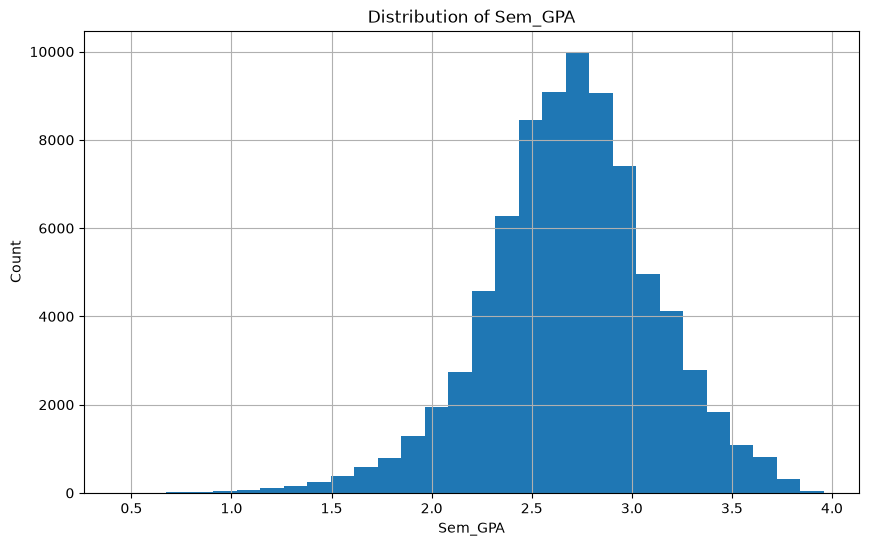

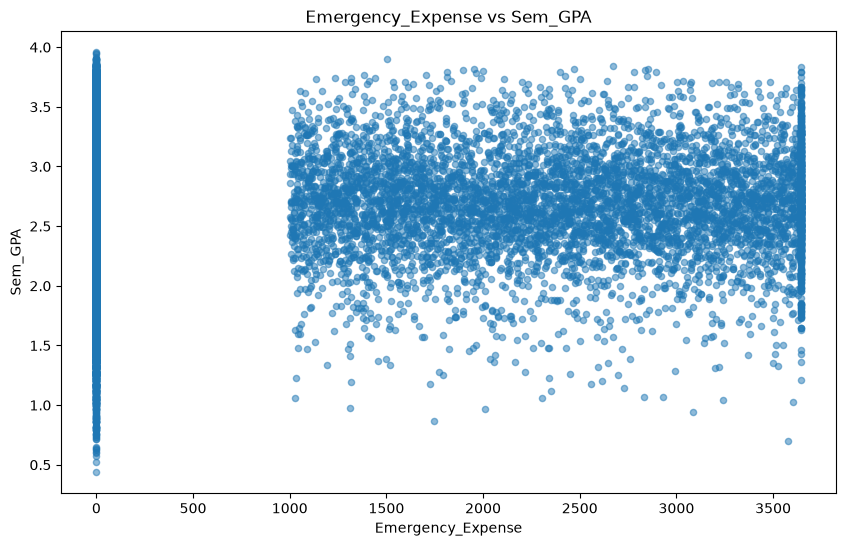

End_of_Semester_Status,Dropped_Out,Enrolled,Graduated
Gender,,,
Female,3471,35213,942
Male,3307,33766,986
Others,97,997,31
Prefer not to say,42,378,9


In [13]:
# Distribution of Sem_GPA
df['Sem_GPA'].hist(bins=30)
plt.title('Distribution of Sem_GPA')
plt.xlabel('Sem_GPA')
plt.ylabel('Count')
plt.show()

# Scatter plot: Emergency_Expense vs Sem_GPA
df.plot.scatter(x='Emergency_Expense', y='Sem_GPA', alpha=0.5)
plt.title('Emergency_Expense vs Sem_GPA')
plt.show()

# End_of_Semester_Status by Gender
pd.crosstab(df['Gender'], df['End_of_Semester_Status'])


In [14]:
# EDA Table 1: Gender Ã— End_of_Semester_Status crosstab with row percentages
t1 = pd.crosstab(df['Gender'], df['End_of_Semester_Status'], margins=True)
t1_pct = t1.div(t1['All'], axis=0).mul(100).round(1)
print('Table 1: Gender Ã— End_of_Semester_Status (% of row)')
print(t1_pct)
print()

# EDA Table 2: Semester Ã— End_of_Semester_Status crosstab
t2 = pd.crosstab(df['Semester'], df['End_of_Semester_Status'], margins=True)
print('Table 2: Semester Ã— End_of_Semester_Status (counts)')
print(t2)
print()

# EDA Table 3: Scholarship Ã— End_of_Semester_Status crosstab with row percentages
t3 = pd.crosstab(df['Scholarship'], df['End_of_Semester_Status'], margins=True)
t3_pct = t3.div(t3['All'], axis=0).mul(100).round(1)
print('Table 3: Scholarship Ã— End_of_Semester_Status (% of row)')
print(t3_pct)
print()

# EDA Table 4: Family_Income binned stats by End_of_Semester_Status
df['Income_Bin'] = pd.qcut(df['Family_Income'], q=4, duplicates='drop')
t4 = df.groupby(['Income_Bin', 'End_of_Semester_Status']).size().unstack(fill_value=0)
t4['Total'] = t4.sum(axis=1)
t4_pct = t4.div(t4['Total'], axis=0).mul(100).round(1)
print('Table 4: Income quartile Ã— End_of_Semester_Status (% of row)')
print(t4_pct)
print()

# EDA Table 5: Summary metrics by Gender
t5 = df.groupby('Gender').agg(
    n_students=('Student_ID', 'nunique'),
    n_rows=('Student_ID', 'size'),
    avg_sem_gpa=('Sem_GPA', 'mean'),
    avg_attendance=('Attendance', 'mean'),
    avg_financial_stress=('Financial_Stress', 'mean'),
    dropout_rate=('Target_Dropout_Next_Sem', 'mean'),
).round(3)
t5['dropout_rate'] = (t5['dropout_rate'] * 100).round(1)
print('Table 5: Summary metrics by Gender')
print(t5)


Table 1: Gender Ã— End_of_Semester_Status (% of row)
End_of_Semester_Status  Dropped_Out  Enrolled  Graduated    All
Gender                                                         
Female                          8.8      88.9        2.4  100.0
Male                            8.7      88.7        2.6  100.0
Others                          8.6      88.6        2.8  100.0
Prefer not to say               9.8      88.1        2.1  100.0
All                             8.7      88.8        2.5  100.0

Table 2: Semester Ã— End_of_Semester_Status (counts)
End_of_Semester_Status  Dropped_Out  Enrolled  Graduated    All
Semester                                                       
1                              1332     18668          0  20000
2                              1473     15123          0  16596
3                              1289     11942          0  13231
4                               950      9289          0  10239
5                               771      6934          0   77

Table 4: Income quartile Ã— End_of_Semester_Status (% of row)
End_of_Semester_Status  Dropped_Out  Enrolled  Graduated  Total
Income_Bin                                                     
(2999.999, 35000.0]            12.8      85.4        1.8  100.0
(35000.0, 52000.0]             10.6      87.3        2.1  100.0
(52000.0, 77000.0]              6.1      91.0        2.9  100.0
(77000.0, 488000.0]             5.1      91.7        3.2  100.0

Table 5: Summary metrics by Gender
                   n_students  n_rows  avg_sem_gpa  avg_attendance  \
Gender                                                               
Female                  10012   39626        2.689          85.064   
Male                     9589   38059        2.694          85.105   
Others                    289    1125        2.687          84.822   
Prefer not to say         110     429        2.683          85.271   

                   avg_financial_stress  dropout_rate  
Gender                                   

Distribution Table A: End_of_Semester_Status
                        Count  Percent
End_of_Semester_Status                
Enrolled                70354     88.8
Dropped_Out              6917      8.7
Graduated                1968      2.5

Distribution Table B: Gender
                   Count  Percent
Gender                           
Female             39626     50.0
Male               38059     48.0
Others              1125      1.4
Prefer not to say    429      0.5

Distribution Table C: Scholarship
             Count  Percent
Scholarship                
0            57249     72.2
1            21990     27.8

Distribution Table D: Semester
          Count  Percent
Semester                
1         20000     25.2
2         16596     20.9
3         13231     16.7
4         10239     12.9
5          7705      9.7
6          5554      7.0
7          3742      4.7
8          2172      2.7


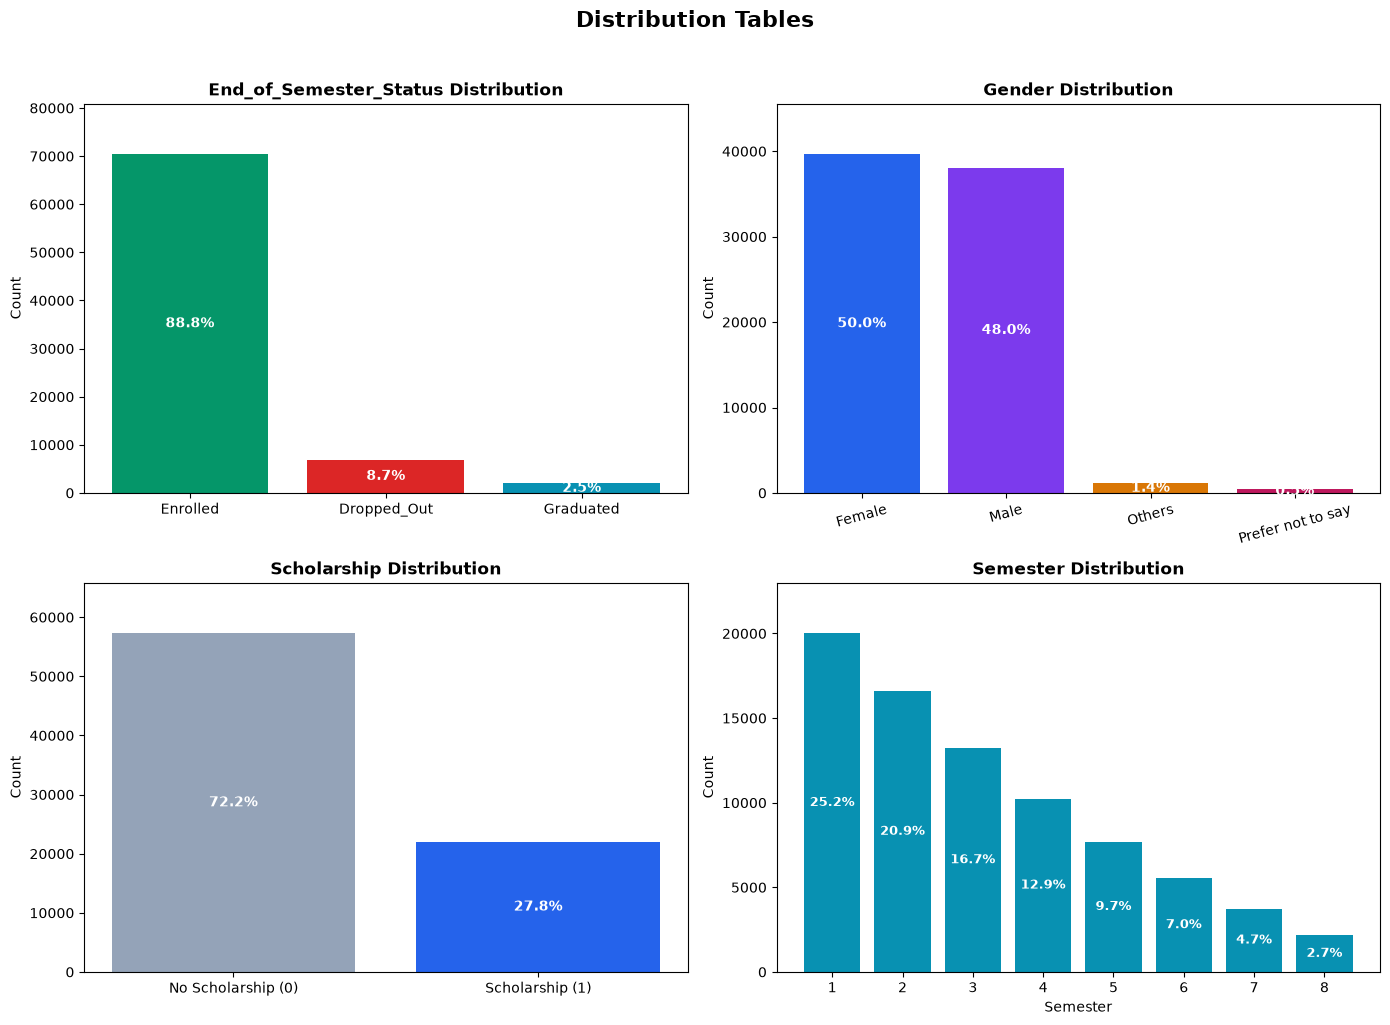

Saved eda_distribution_tables.png


In [15]:
# Distribution Tables (counts & percentages)
dist_status = df['End_of_Semester_Status'].value_counts()
dist_status_pct = (dist_status / len(df) * 100).round(1)
dist_status_df = pd.DataFrame({'Count': dist_status, 'Percent': dist_status_pct})
print('Distribution Table A: End_of_Semester_Status')
print(dist_status_df)
print()

dist_gender = df['Gender'].value_counts()
dist_gender_pct = (dist_gender / len(df) * 100).round(1)
dist_gender_df = pd.DataFrame({'Count': dist_gender, 'Percent': dist_gender_pct})
print('Distribution Table B: Gender')
print(dist_gender_df)
print()

dist_scholarship = df['Scholarship'].value_counts()
dist_scholarship_pct = (dist_scholarship / len(df) * 100).round(1)
dist_scholarship_df = pd.DataFrame({'Count': dist_scholarship, 'Percent': dist_scholarship_pct})
print('Distribution Table C: Scholarship')
print(dist_scholarship_df)
print()

dist_semester = df['Semester'].value_counts().sort_index()
dist_semester_pct = (dist_semester / len(df) * 100).round(1)
dist_semester_df = pd.DataFrame({'Count': dist_semester, 'Percent': dist_semester_pct})
print('Distribution Table D: Semester')
print(dist_semester_df)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribution Tables', fontsize=16, weight='bold', y=1.02)

colors_status = {'Enrolled': '#059669', 'Dropped_Out': '#dc2626', 'Graduated': '#0891b2'}
ax = axes[0, 0]
bars = ax.bar(dist_status.index, dist_status.values, color=[colors_status.get(x, '#64748b') for x in dist_status.index])
ax.set_title('End_of_Semester_Status Distribution', weight='bold')
ax.set_ylabel('Count')
for i, (idx, val) in enumerate(dist_status.items()):
    ax.text(i, val/2, f'{dist_status_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=10)
ax.set_ylim(0, max(dist_status.values) * 1.15)

colors_g = {'Female': '#2563eb', 'Male': '#7c3aed', 'Others': '#d97706', 'Prefer not to say': '#be185d'}
ax = axes[0, 1]
bars = ax.bar(dist_gender.index, dist_gender.values, color=[colors_g.get(x, '#64748b') for x in dist_gender.index])
ax.set_title('Gender Distribution', weight='bold')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=15)
for i, (idx, val) in enumerate(dist_gender.items()):
    ax.text(i, val/2, f'{dist_gender_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=10)
ax.set_ylim(0, max(dist_gender.values) * 1.15)

ax = axes[1, 0]
labels_scholarship = ['No Scholarship (0)', 'Scholarship (1)']
bars = ax.bar(labels_scholarship, dist_scholarship.values, color=['#94a3b8', '#2563eb'])
ax.set_title('Scholarship Distribution', weight='bold')
ax.set_ylabel('Count')
for i, (idx, val) in enumerate(dist_scholarship.items()):
    ax.text(i, val/2, f'{dist_scholarship_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=10)
ax.set_ylim(0, max(dist_scholarship.values) * 1.15)

ax = axes[1, 1]
ax.bar(dist_semester.index, dist_semester.values, color='#0891b2')
ax.set_title('Semester Distribution', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Count')
ax.set_xticks(dist_semester.index)
for i, (idx, val) in enumerate(dist_semester.items()):
    ax.text(idx, val/2, f'{dist_semester_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=9)
ax.set_ylim(0, max(dist_semester.values) * 1.15)

plt.tight_layout()
plt.savefig('eda_distribution_tables.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_distribution_tables.png')


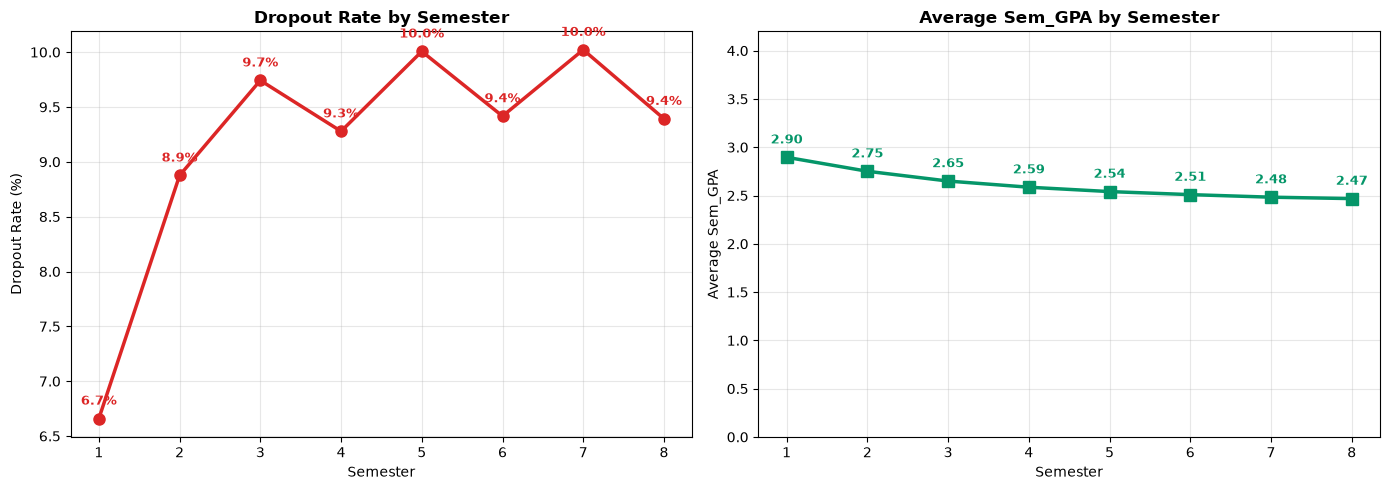

Saved eda_line_charts_trends.png


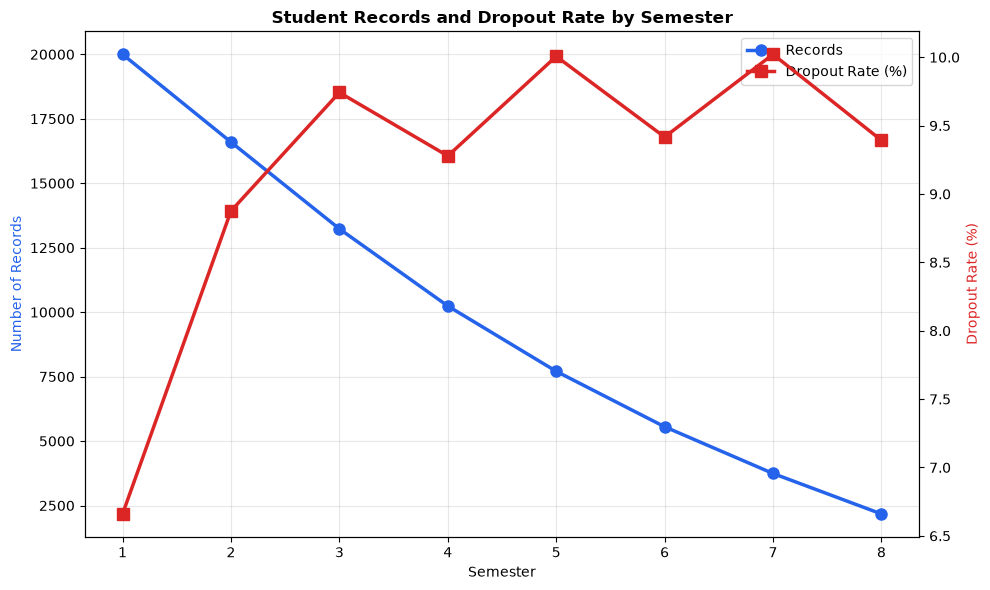

Saved eda_line_chart_enrollment_dropout.png


In [16]:
# Line Charts: trends over semesters
semester_stats = df.groupby('Semester').agg(
    dropout_rate=('Target_Dropout_Next_Sem', 'mean'),
    avg_gpa=('Sem_GPA', 'mean'),
    n=('Student_ID', 'size')
).reset_index()
semester_stats['dropout_rate_pct'] = semester_stats['dropout_rate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(semester_stats['Semester'], semester_stats['dropout_rate_pct'], marker='o', linewidth=2.5, markersize=8, color='#dc2626')
ax.set_title('Dropout Rate by Semester', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Dropout Rate (%)')
ax.set_xticks(semester_stats['Semester'])
ax.grid(True, alpha=0.3)
for _, row in semester_stats.iterrows():
    ax.annotate(f'{row["dropout_rate_pct"]:.1f}%', (row['Semester'], row['dropout_rate_pct']),
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, weight='bold', color='#dc2626')

ax = axes[1]
ax.plot(semester_stats['Semester'], semester_stats['avg_gpa'], marker='s', linewidth=2.5, markersize=8, color='#059669')
ax.set_title('Average Sem_GPA by Semester', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Average Sem_GPA')
ax.set_xticks(semester_stats['Semester'])
ax.set_ylim(0, 4.2)
ax.grid(True, alpha=0.3)
for _, row in semester_stats.iterrows():
    ax.annotate(f'{row["avg_gpa"]:.2f}', (row['Semester'], row['avg_gpa']),
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, weight='bold', color='#059669')

plt.tight_layout()
plt.savefig('eda_line_charts_trends.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_line_charts_trends.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax2 = ax.twinx()
line1 = ax.plot(semester_stats['Semester'], semester_stats['n'], marker='o', linewidth=2.5, markersize=8, color='#2563eb', label='Records')
line2 = ax2.plot(semester_stats['Semester'], semester_stats['dropout_rate_pct'], marker='s', linewidth=2.5, markersize=8, color='#dc2626', label='Dropout Rate (%)')
ax.set_title('Student Records and Dropout Rate by Semester', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Number of Records', color='#2563eb')
ax2.set_ylabel('Dropout Rate (%)', color='#dc2626')
ax.set_xticks(semester_stats['Semester'])
ax.grid(True, alpha=0.3)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc='upper right')
plt.tight_layout()
plt.savefig('eda_line_chart_enrollment_dropout.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_line_chart_enrollment_dropout.png')


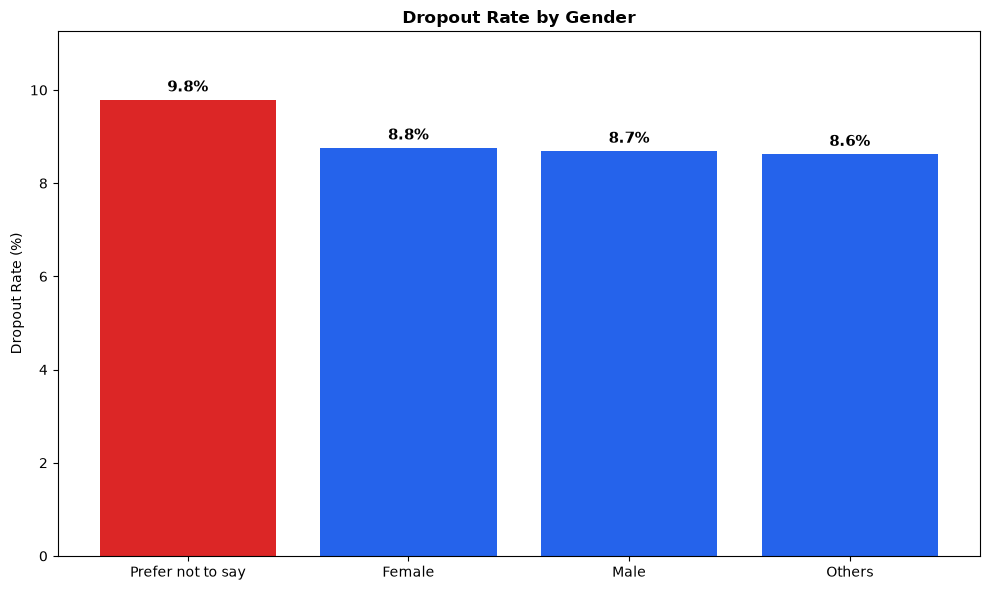

Saved eda_bar_dropout_by_gender.png


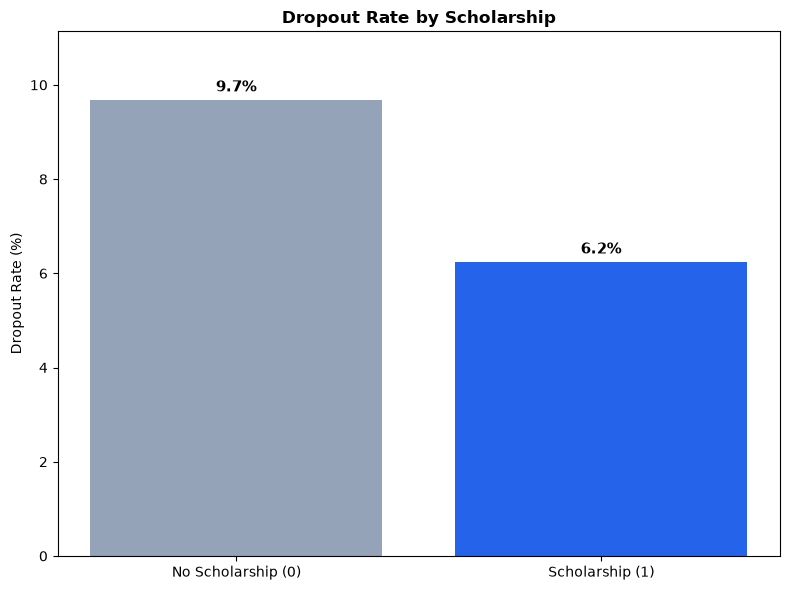

Saved eda_bar_dropout_by_scholarship.png


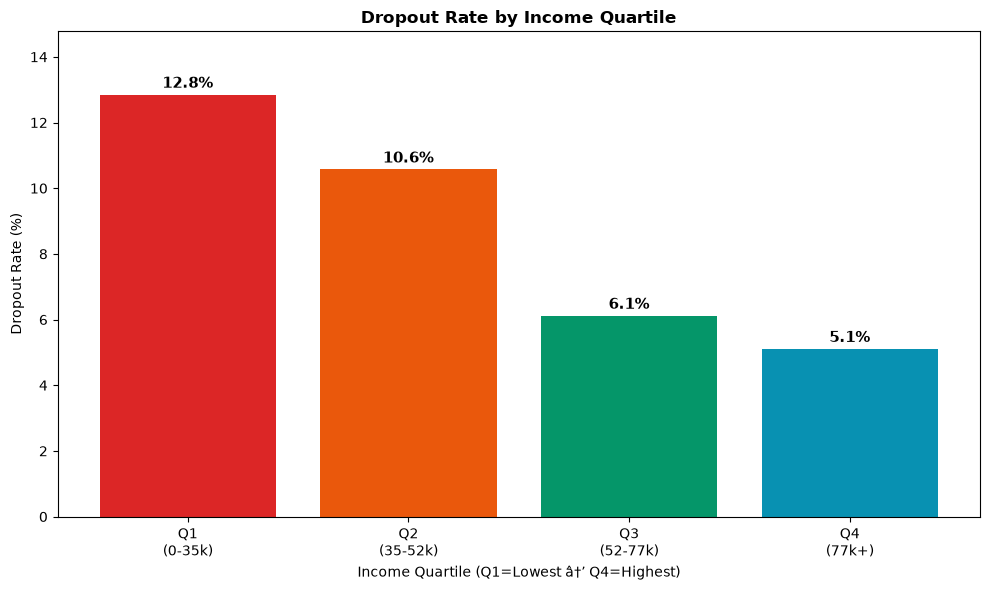

Saved eda_bar_dropout_by_income.png


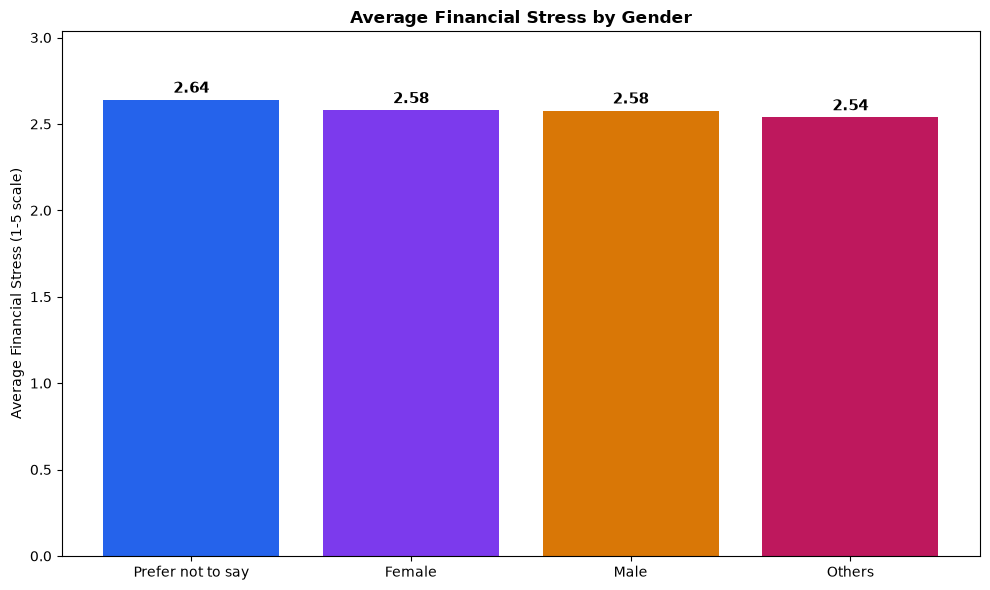

Saved eda_bar_stress_by_gender.png


In [17]:
# Bar Graphs: dropout rate by category
gender_dropout = df.groupby('Gender')['Target_Dropout_Next_Sem'].mean() * 100
gender_dropout = gender_dropout.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
colors_bar1 = ['#dc2626' if v == gender_dropout.max() else '#2563eb' for v in gender_dropout.values]
bars = ax.bar(gender_dropout.index, gender_dropout.values, color=colors_bar1)
ax.set_title('Dropout Rate by Gender', weight='bold')
ax.set_ylabel('Dropout Rate (%)')
ax.set_ylim(0, max(gender_dropout.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_dropout_by_gender.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_dropout_by_gender.png')

scholarship_dropout = df.groupby('Scholarship')['Target_Dropout_Next_Sem'].mean() * 100
scholarship_dropout.index = ['No Scholarship (0)', 'Scholarship (1)']

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(scholarship_dropout.index, scholarship_dropout.values, color=['#94a3b8', '#2563eb'])
ax.set_title('Dropout Rate by Scholarship', weight='bold')
ax.set_ylabel('Dropout Rate (%)')
ax.set_ylim(0, max(scholarship_dropout.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_dropout_by_scholarship.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_dropout_by_scholarship.png')

df['Income_Bin'] = pd.qcut(df['Family_Income'], q=4, duplicates='drop')
income_dropout = df.groupby('Income_Bin')['Target_Dropout_Next_Sem'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(range(len(income_dropout)), income_dropout.values, color=['#dc2626', '#ea580c', '#059669', '#0891b2'])
ax.set_title('Dropout Rate by Income Quartile', weight='bold')
ax.set_ylabel('Dropout Rate (%)')
ax.set_xlabel('Income Quartile (Q1=Lowest â†’ Q4=Highest)')
ax.set_xticks(range(len(income_dropout)))
ax.set_xticklabels(['Q1\n(0-35k)', 'Q2\n(35-52k)', 'Q3\n(52-77k)', 'Q4\n(77k+)'], fontsize=10)
ax.set_ylim(0, max(income_dropout.values) * 1.15)
for i, bar in enumerate(bars):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_dropout_by_income.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_dropout_by_income.png')

gender_stress = df.groupby('Gender')['Financial_Stress'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(gender_stress.index, gender_stress.values, color=['#2563eb', '#7c3aed', '#d97706', '#be185d'])
ax.set_title('Average Financial Stress by Gender', weight='bold')
ax.set_ylabel('Average Financial Stress (1-5 scale)')
ax.set_ylim(0, max(gender_stress.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f'{h:.2f}', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_stress_by_gender.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_stress_by_gender.png')


In [18]:
# ========== FEATURE ENGINEERING WITH UNIFIED CATEGORICAL ENCODING ==========
df_fe = df.copy()
df_fe = df_fe.sort_values(['Student_ID', 'Semester']).reset_index(drop=True)

# --- Unified Categorical Encoding (Ordinal) ---
# Define explicit orderings for each categorical feature
cat_encodings = {
    'Gender': {'Prefer not to say': 0, 'Others': 1, 'F': 2, 'female': 2, 'Female': 2, 'M': 3, 'male': 3, 'Male': 3},
    'Housing_Status': {'With Parents': 0, 'Off-Campus': 1, 'On-Campus': 2},
    'End_of_Semester_Status': {'Dropped_Out': 0, 'Enrolled': 1, 'Graduated': 2}
}

# Apply mappings - unmapped values become NaN (then fill with median)
for col, mapping in cat_encodings.items():
    if col in df_fe.columns:
        df_fe[f'{col}_encoded'] = df_fe[col].map(mapping)
        df_fe[f'{col}_encoded'] = df_fe[f'{col}_encoded'].fillna(df_fe[f'{col}_encoded'].median())
        print(f'{col}: mapped {df_fe[col].nunique()} categories -> {col}_encoded')

# --- Lag features (previous semester values) ---
lag_cols = ['Sem_GPA', 'Attendance', 'Financial_Stress', 'Emergency_Expense',
            'Work_Hours', 'Course_Load', 'LMS_Logins', 'Advising_Visits',
            'Failed_Courses']
for col in lag_cols:
    if col in df_fe.columns:
        df_fe[f'{col}_lag1'] = df_fe.groupby('Student_ID')[col].shift(1)
        df_fe[f'{col}_lag2'] = df_fe.groupby('Student_ID')[col].shift(2)

# --- Rolling statistics (window=2,3) ---
for col in ['Sem_GPA', 'Attendance', 'Financial_Stress']:
    if col in df_fe.columns:
        df_fe[f'{col}_roll2_mean'] = df_fe.groupby('Student_ID')[col].transform(lambda x: x.rolling(2, min_periods=1).mean())
        df_fe[f'{col}_roll2_std'] = df_fe.groupby('Student_ID')[col].transform(lambda x: x.rolling(2, min_periods=1).std())
        df_fe[f'{col}_roll3_mean'] = df_fe.groupby('Student_ID')[col].transform(lambda x: x.rolling(3, min_periods=1).mean())
        df_fe[f'{col}_roll3_std'] = df_fe.groupby('Student_ID')[col].transform(lambda x: x.rolling(3, min_periods=1).std())

# --- Trend features (difference from previous semester) ---
for col in ['Sem_GPA', 'Attendance', 'Financial_Stress']:
    if col in df_fe.columns:
        df_fe[f'{col}_diff1'] = df_fe.groupby('Student_ID')[col].diff(1)
        df_fe[f'{col}_diff2'] = df_fe.groupby('Student_ID')[col].diff(2)

# --- Cumulative features ---
df_fe['cum_failed_courses'] = df_fe.groupby('Student_ID')['Failed_Courses'].cumsum()
df_fe['cum_emergency_expense'] = df_fe.groupby('Student_ID')['Emergency_Expense'].cumsum()
df_fe['cum_advising_visits'] = df_fe.groupby('Student_ID')['Advising_Visits'].cumsum()

# --- Interaction features ---
df_fe['work_study_ratio'] = df_fe['Work_Hours'] / (df_fe['Course_Load'] + 1)
df_fe['stress_income_ratio'] = df_fe['Financial_Stress'] / (df_fe['Family_Income'] / 10000 + 1)
df_fe['gpa_attendance_interaction'] = df_fe['Sem_GPA'] * df_fe['Attendance']
df_fe['scholarship_gpa_interaction'] = df_fe['Scholarship'] * df_fe['Sem_GPA']

# --- Semester position features ---
df_fe['semester_since_start'] = df_fe.groupby('Student_ID').cumcount() + 1
df_fe['total_semesters_per_student'] = df_fe.groupby('Student_ID')['Semester'].transform('nunique')
df_fe['semester_progress_pct'] = df_fe['semester_since_start'] / df_fe['total_semesters_per_student']

# Target: next semester dropout
df_fe['target'] = df_fe['Target_Dropout_Next_Sem']

print(f'\nOriginal features: {len(df.columns)}')
print(f'Engineered features: {len(df_fe.columns)}')
print(f'New features added: {len(df_fe.columns) - len(df.columns)}')

# Save for feature selection
import pickle
with open('df_fe.pkl', 'wb') as f:
    pickle.dump(df_fe, f)
print('Saved df_fe.pkl for feature selection')


Gender: mapped 4 categories -> Gender_encoded


Housing_Status: mapped 3 categories -> Housing_Status_encoded
End_of_Semester_Status: mapped 3 categories -> End_of_Semester_Status_encoded



Original features: 24
Engineered features: 74
New features added: 50
Saved df_fe.pkl for feature selection


Feature matrix shape: (41224, 65)
Target distribution: {0: 37242, 1: 3982}

Top 20 features by correlation with target:
End_of_Semester_Status_encoded    0.829270
semester_progress_pct             0.380317
total_semesters_per_student       0.321442
Sem_GPA                           0.271960
gpa_attendance_interaction        0.256160
Sem_GPA_roll2_mean                0.247234
Financial_Stress                  0.230283
Financial_Stress_roll2_mean       0.228379
Financial_Stress_roll3_mean       0.226706
Sem_GPA_roll3_mean                0.223079
Failed_Courses                    0.213846
stress_income_ratio               0.213356
Sem_GPA_lag1                      0.213073
Financial_Stress_lag1             0.195905
Financial_Stress_lag2             0.192076
Sem_GPA_roll3_std                 0.171587
Sem_GPA_roll2_std                 0.166002
Sem_GPA_lag2                      0.162343
Sem_GPA_diff2                     0.155131
Sem_GPA_diff1                     0.150634
dtype: float64



Highly correlated feature pairs (>0.9): 20
  Sem_GPA_lag1 - Sem_GPA: 0.924
  Sem_GPA_lag2 - Sem_GPA_lag1: 0.925
  Sem_GPA_roll2_mean - Sem_GPA: 0.981
  Sem_GPA_roll2_mean - Sem_GPA_lag1: 0.981
  Sem_GPA_roll3_mean - Sem_GPA: 0.947
  Sem_GPA_roll3_mean - Sem_GPA_lag1: 0.987
  Sem_GPA_roll3_mean - Sem_GPA_lag2: 0.952
  Sem_GPA_roll3_mean - Sem_GPA_roll2_mean: 0.986
  Attendance_roll3_mean - Attendance_roll2_mean: 0.942
  Financial_Stress_roll2_mean - Financial_Stress: 0.935



Top 20 features by Mutual Information:
                           feature  mi_score
18  End_of_Semester_Status_encoded  0.325091
64           semester_progress_pct  0.125978
63     total_semesters_per_student  0.055509
60      gpa_attendance_interaction  0.035169
10                         Sem_GPA  0.032509
37              Sem_GPA_roll2_mean  0.028246
39              Sem_GPA_roll3_mean  0.022517
14                  Failed_Courses  0.022266
45     Financial_Stress_roll2_mean  0.021641
47     Financial_Stress_roll3_mean  0.021576
19                    Sem_GPA_lag1  0.021415
15                Financial_Stress  0.021092
59             stress_income_ratio  0.019387
23           Financial_Stress_lag1  0.018054
58                work_study_ratio  0.015994
20                    Sem_GPA_lag2  0.015727
40               Sem_GPA_roll3_std  0.015536
24           Financial_Stress_lag2  0.014775
50                   Sem_GPA_diff2  0.013037
38               Sem_GPA_roll2_std  0.012579



Top 20 features by Random Forest Importance:
                           feature  importance
18  End_of_Semester_Status_encoded    0.543585
64           semester_progress_pct    0.224471
63     total_semesters_per_student    0.058756
60      gpa_attendance_interaction    0.020615
10                         Sem_GPA    0.015206
37              Sem_GPA_roll2_mean    0.012603
14                  Failed_Courses    0.010400
39              Sem_GPA_roll3_mean    0.010061
6                         Semester    0.009622
45     Financial_Stress_roll2_mean    0.009061
62            semester_since_start    0.008938
15                Financial_Stress    0.007386
59             stress_income_ratio    0.007253
19                    Sem_GPA_lag1    0.005560
47     Financial_Stress_roll3_mean    0.005546
40               Sem_GPA_roll3_std    0.003680
49                   Sem_GPA_diff1    0.003311
61     scholarship_gpa_interaction    0.003176
1                 First_Generation    0.002776
55            

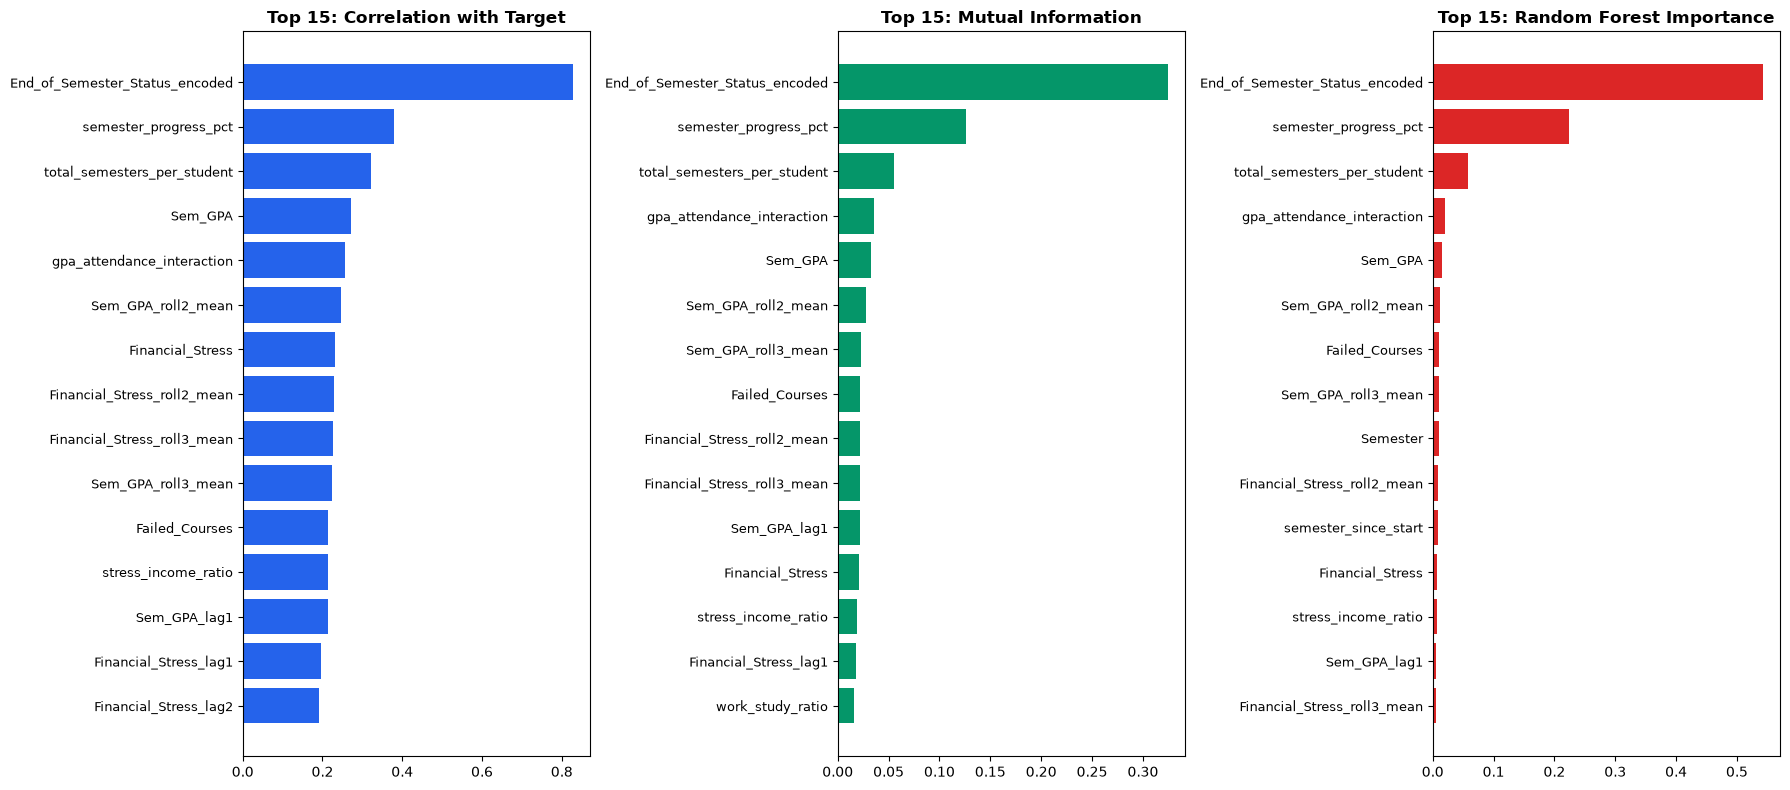

Saved feature_selection_importance.png


In [19]:
# ========== FEATURE SELECTION ==========
import pickle
with open('df_fe.pkl', 'rb') as f:
    df_fe = pickle.load(f)

# Prepare features and target
exclude_cols = ['Student_ID', 'End_of_Semester_Status', 'Target_Dropout_Next_Sem',
                'Censored', 'Income_Bin', 'sem_gpa_invalid', 'target',
                'Gender', 'Housing_Status']  # use encoded versions instead
feature_cols = [c for c in df_fe.columns if c not in exclude_cols and df_fe[c].dtype in ['int64', 'float64', 'int32', 'float32']]

# Drop rows with NaN in features (from lag/rolling)
df_fs = df_fe[feature_cols + ['target']].dropna()
X = df_fs[feature_cols]
y = df_fs['target']

print(f'Feature matrix shape: {X.shape}')
print(f'Target distribution: {y.value_counts().to_dict()}')

# 1. Correlation with target
corr_with_target = X.corrwith(y).abs().sort_values(ascending=False)
print('\nTop 20 features by correlation with target:')
print(corr_with_target.head(20))

# 2. Feature correlation matrix (multicollinearity check)
corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(col, row) for col in upper.columns for row in upper.index if upper.loc[row, col] > 0.9]
print(f'\nHighly correlated feature pairs (>0.9): {len(high_corr_pairs)}')
for pair in high_corr_pairs[:10]:
    print(f'  {pair[0]} - {pair[1]}: {corr_matrix.loc[pair[0], pair[1]]:.3f}')

# 3. Mutual Information
from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({'feature': X.columns, 'mi_score': mi_scores})
mi_df = mi_df.sort_values('mi_score', ascending=False)
print('\nTop 20 features by Mutual Information:')
print(mi_df.head(20))

# 4. Random Forest Feature Importance
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X, y)
importance_df = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
importance_df = importance_df.sort_values('importance', ascending=False)
print('\nTop 20 features by Random Forest Importance:')
print(importance_df.head(20))

# 5. Select top features combining all methods (voting >= 2)
top_corr = set(corr_with_target.head(30).index)
top_mi = set(mi_df.head(30)['feature'].values)
top_rf = set(importance_df.head(30)['feature'].values)

all_top = list(top_corr | top_mi | top_rf)
feature_votes = {}
for f in all_top:
    votes = sum([f in top_corr, f in top_mi, f in top_rf])
    feature_votes[f] = votes

selected_features = [f for f, v in feature_votes.items() if v >= 2]
print(f'\nFeatures selected by >=2 methods: {len(selected_features)}')
for f in sorted(selected_features, key=lambda x: feature_votes[x], reverse=True):
    print(f'  {f}: {feature_votes[f]} votes')

# Save selected features
with open('selected_features.pkl', 'wb') as f:
    pickle.dump(selected_features, f)
with open('feature_importance.pkl', 'wb') as f:
    pickle.dump({'correlation': corr_with_target, 'mi': mi_df.set_index('feature')['mi_score'], 'rf': importance_df.set_index('feature')['importance']}, f)
print('\nSaved selected_features.pkl and feature_importance.pkl')

# 6. Visualize feature importance
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

top15_corr = corr_with_target.head(15)
axes[0].barh(range(len(top15_corr)), top15_corr.values, color='#2563eb')
axes[0].set_yticks(range(len(top15_corr)))
axes[0].set_yticklabels(top15_corr.index, fontsize=9)
axes[0].set_title('Top 15: Correlation with Target', weight='bold')
axes[0].invert_yaxis()

top15_mi = mi_df.head(15)
axes[1].barh(range(len(top15_mi)), top15_mi['mi_score'].values, color='#059669')
axes[1].set_yticks(range(len(top15_mi)))
axes[1].set_yticklabels(top15_mi['feature'].values, fontsize=9)
axes[1].set_title('Top 15: Mutual Information', weight='bold')
axes[1].invert_yaxis()

top15_rf = importance_df.head(15)
axes[2].barh(range(len(top15_rf)), top15_rf['importance'].values, color='#dc2626')
axes[2].set_yticks(range(len(top15_rf)))
axes[2].set_yticklabels(top15_rf['feature'].values, fontsize=9)
axes[2].set_title('Top 15: Random Forest Importance', weight='bold')
axes[2].invert_yaxis()

plt.tight_layout()
plt.savefig('feature_selection_importance.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved feature_selection_importance.png')


Feature matrix: (42643, 38)
Target distribution: {0: 38531, 1: 4112}


Unique students: 13231
Features: 38



========== MODEL PERFORMANCE (GroupKFold CV) - NO LEAKAGE ==========
ROC-AUC:       0.9511
PR-AUC:        0.6652
F1 Score:      0.5242
Precision:     0.3599
Recall:        0.9643
Brier Score:   0.1040
Baseline PR-AUC (random): 0.0964

Classification Report:
              precision    recall  f1-score   support

    Retained       1.00      0.82      0.90     38531
     Dropout       0.36      0.96      0.52      4112

    accuracy                           0.83     42643
   macro avg       0.68      0.89      0.71     42643
weighted avg       0.93      0.83      0.86     42643

Confusion Matrix:
[[31479  7052]
 [  147  3965]]



========== TOP 20 FEATURE COEFFICIENTS ==========
                    feature  coefficient  abs_coef
      semester_progress_pct     9.332958  9.332958
total_semesters_per_student    -0.541900  0.541900
 gpa_attendance_interaction    -0.488806  0.488806
             Failed_Courses     0.451383  0.451383
                 Work_Hours     0.345089  0.345089
           work_study_ratio    -0.306779  0.306779
           Financial_Stress     0.275544  0.275544
scholarship_gpa_interaction    -0.268604  0.268604
Financial_Stress_roll2_mean     0.111306  0.111306
      Financial_Stress_lag1    -0.070235  0.070235
      Financial_Stress_lag2    -0.067046  0.067046
            Work_Hours_lag2    -0.052626  0.052626
Financial_Stress_roll3_mean     0.051973  0.051973
              Gender_Others    -0.047092  0.047092
        cum_advising_visits    -0.046487  0.046487
   Gender_Prefer not to say     0.040734  0.040734
        stress_income_ratio    -0.035900  0.035900
              Family_Income    

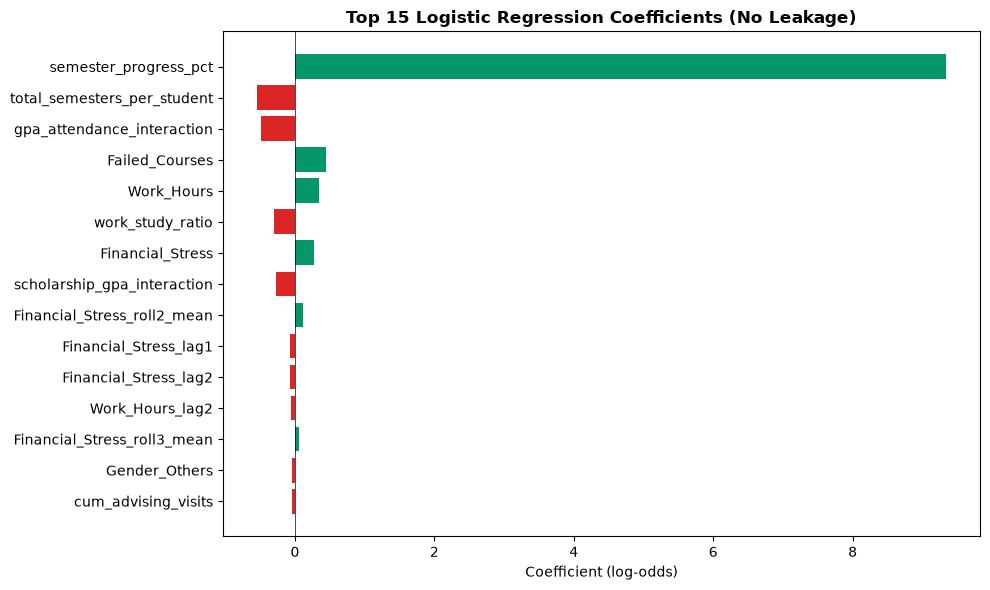

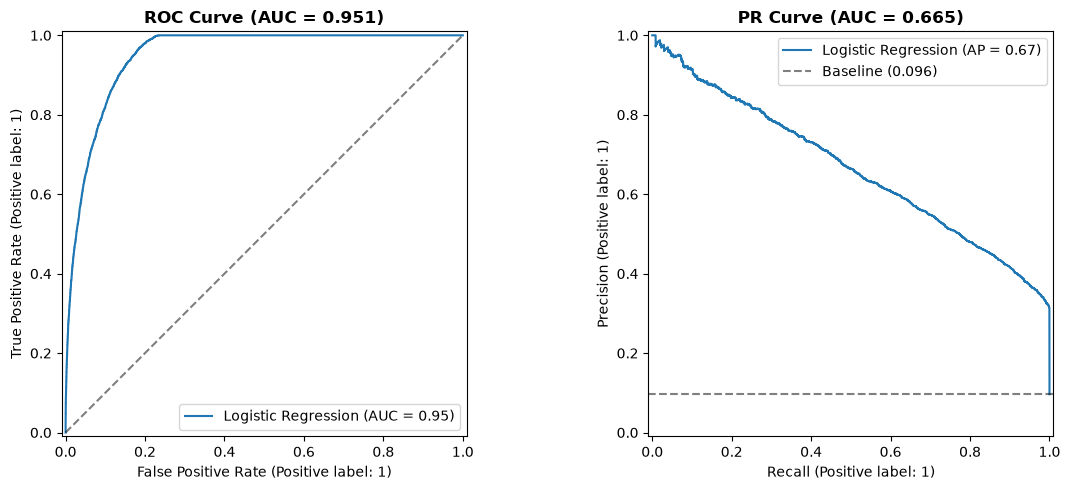

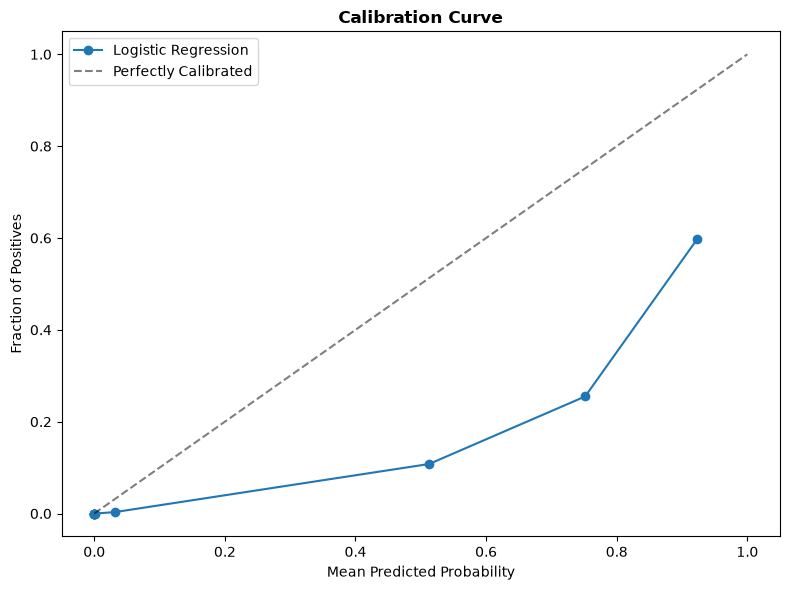

Saved: lr_coefficients_no_leakage.png, lr_roc_pr_curves_no_leakage.png, lr_calibration_no_leakage.png


In [20]:
# ========== LOGISTIC REGRESSION MODEL (NO LEAKAGE) ==========
import pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, 
                             f1_score, precision_score, recall_score,
                             brier_score_loss, classification_report,
                             confusion_matrix)

# Load engineered features
with open('df_fe.pkl', 'rb') as f:
    df_fe = pickle.load(f)

# Load selected features
with open('selected_features.pkl', 'rb') as f:
    selected_features = pickle.load(f)

# Prepare data with ONE-HOT encoding for nominal categoricals
# Nominal: Gender, Housing_Status -> one-hot
# EXCLUDE: End_of_Semester_Status_encoded (leakage - current status predicting next semester)
df_model = df_fe.copy()

# One-hot encode nominal categoricals
df_model = pd.get_dummies(df_model, 
                          columns=['Gender', 'Housing_Status'], 
                          prefix=['Gender', 'Housing'], 
                          drop_first=False,
                          dtype=int)

# Identify feature columns (selected + one-hot expanded)
onehot_cols = [c for c in df_model.columns if c.startswith('Gender_') or c.startswith('Housing_')]
feat_cols = [c for c in selected_features if c in df_model.columns] + onehot_cols

# Exclude raw categoricals, leakage columns, and End_of_Semester_Status_encoded
exclude = ['Student_ID', 'End_of_Semester_Status', 'Target_Dropout_Next_Sem',
           'Censored', 'Income_Bin', 'sem_gpa_invalid', 'target',
           'Gender', 'Housing_Status', 'End_of_Semester_Status_encoded']
feat_cols = [c for c in feat_cols if c not in exclude and df_model[c].dtype in ['int64', 'float64', 'int32', 'float32', 'uint8']]

# Drop NaN rows (from lag/rolling features)
df_clean = df_model[feat_cols + ['target', 'Student_ID']].dropna()
X = df_clean[feat_cols]
y = df_clean['target']
groups = df_clean['Student_ID']

print(f'Feature matrix: {X.shape}')
print(f'Target distribution: {y.value_counts().to_dict()}')
print(f'Unique students: {groups.nunique()}')
print(f'Features: {len(feat_cols)}')

# Pipeline: StandardScaler + LogisticRegression
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
        solver='lbfgs',
        C=1.0
    ))
])

# Grouped Cross-Validation (5 folds)
gkf = GroupKFold(n_splits=5)

# Cross-validated predictions for evaluation
y_pred_proba = cross_val_predict(pipe, X, y, cv=gkf, groups=groups, 
                                 method='predict_proba', n_jobs=-1)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

# Metrics
roc_auc = roc_auc_score(y, y_pred_proba)
pr_auc = average_precision_score(y, y_pred_proba)
f1 = f1_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
brier = brier_score_loss(y, y_pred_proba)

print('\n========== MODEL PERFORMANCE (GroupKFold CV) - NO LEAKAGE ==========')
print(f'ROC-AUC:       {roc_auc:.4f}')
print(f'PR-AUC:        {pr_auc:.4f}')
print(f'F1 Score:      {f1:.4f}')
print(f'Precision:     {precision:.4f}')
print(f'Recall:        {recall:.4f}')
print(f'Brier Score:   {brier:.4f}')
print(f'Baseline PR-AUC (random): {y.mean():.4f}')

print('\nClassification Report:')
print(classification_report(y, y_pred, target_names=['Retained', 'Dropout']))

print('Confusion Matrix:')
cm = confusion_matrix(y, y_pred)
print(cm)

# Fit on full data for coefficient inspection
pipe.fit(X, y)

# Feature coefficients
coef_df = pd.DataFrame({
    'feature': feat_cols,
    'coefficient': pipe.named_steps['model'].coef_[0]
})
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False)

print('\n========== TOP 20 FEATURE COEFFICIENTS ==========')
print(coef_df.head(20).to_string(index=False))

# Save model
with open('lr_model_no_leakage.pkl', 'wb') as f:
    pickle.dump(pipe, f)
print('\nSaved lr_model_no_leakage.pkl')

# ========== VISUALIZATIONS ==========
import matplotlib.pyplot as plt

# 1. Coefficient plot
top15_coef = coef_df.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#dc2626' if c < 0 else '#059669' for c in top15_coef['coefficient']]
ax.barh(range(len(top15_coef)), top15_coef['coefficient'], color=colors)
ax.set_yticks(range(len(top15_coef)))
ax.set_yticklabels(top15_coef['feature'], fontsize=10)
ax.set_xlabel('Coefficient (log-odds)')
ax.set_title('Top 15 Logistic Regression Coefficients (No Leakage)', weight='bold')
ax.axvline(0, color='black', linewidth=0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('lr_coefficients_no_leakage.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# 2. ROC Curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y, y_pred_proba, ax=axes[0], name='Logistic Regression')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title(f'ROC Curve (AUC = {roc_auc:.3f})', weight='bold')

PrecisionRecallDisplay.from_predictions(y, y_pred_proba, ax=axes[1], name='Logistic Regression')
axes[1].axhline(y.mean(), color='k', linestyle='--', alpha=0.5, label=f'Baseline ({y.mean():.3f})')
axes[1].legend()
axes[1].set_title(f'PR Curve (AUC = {pr_auc:.3f})', weight='bold')

plt.tight_layout()
plt.savefig('lr_roc_pr_curves_no_leakage.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# 3. Calibration plot
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(8, 6))
prob_true, prob_pred = calibration_curve(y, y_pred_proba, n_bins=10, strategy='quantile')
ax.plot(prob_pred, prob_true, 'o-', label='Logistic Regression')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfectly Calibrated')
ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Fraction of Positives')
ax.set_title('Calibration Curve', weight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('lr_calibration_no_leakage.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print('Saved: lr_coefficients_no_leakage.png, lr_roc_pr_curves_no_leakage.png, lr_calibration_no_leakage.png')


Feature matrix: (42643, 38)
Target distribution: {0: 38531, 1: 4112}
Unique students: 13231
Features: 38

--- Logistic Regression ---


  ROC-AUC:  0.9511
  PR-AUC:   0.6652
  F1:       0.5242
  Precision:0.3599
  Recall:   0.9643
  Brier:    0.1040

--- Naive Bayes ---


  ROC-AUC:  0.9403
  PR-AUC:   0.5877
  F1:       0.5463
  Precision:0.4007
  Recall:   0.8580
  Brier:    0.1218

--- Decision Tree ---


  ROC-AUC:  0.9325
  PR-AUC:   0.5958
  F1:       0.5159
  Precision:0.3539
  Recall:   0.9516
  Brier:    0.1066

--- Random Forest ---


  ROC-AUC:  0.9490
  PR-AUC:   0.6485
  F1:       0.5420
  Precision:0.3807
  Recall:   0.9409
  Brier:    0.0887

========== MODEL COMPARISON SUMMARY ==========
                     roc_auc  pr_auc      f1  precision  recall   brier
Logistic Regression   0.9511  0.6652  0.5242     0.3599  0.9643  0.1040
Random Forest         0.9490  0.6485  0.5420     0.3807  0.9409  0.0887
Naive Bayes           0.9403  0.5877  0.5463     0.4007  0.8580  0.1218
Decision Tree         0.9325  0.5958  0.5159     0.3539  0.9516  0.1066

Saved model_comparison_results.pkl


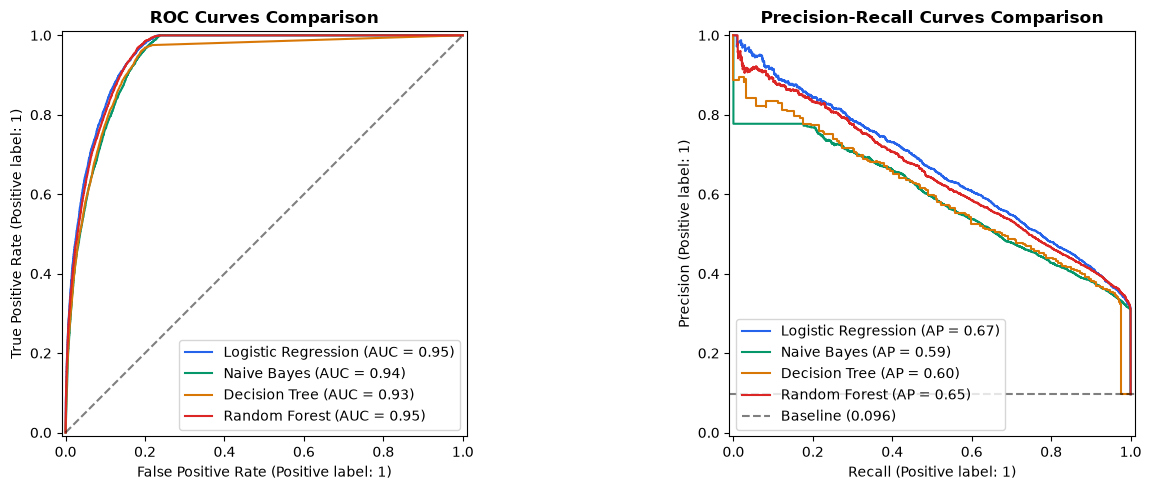

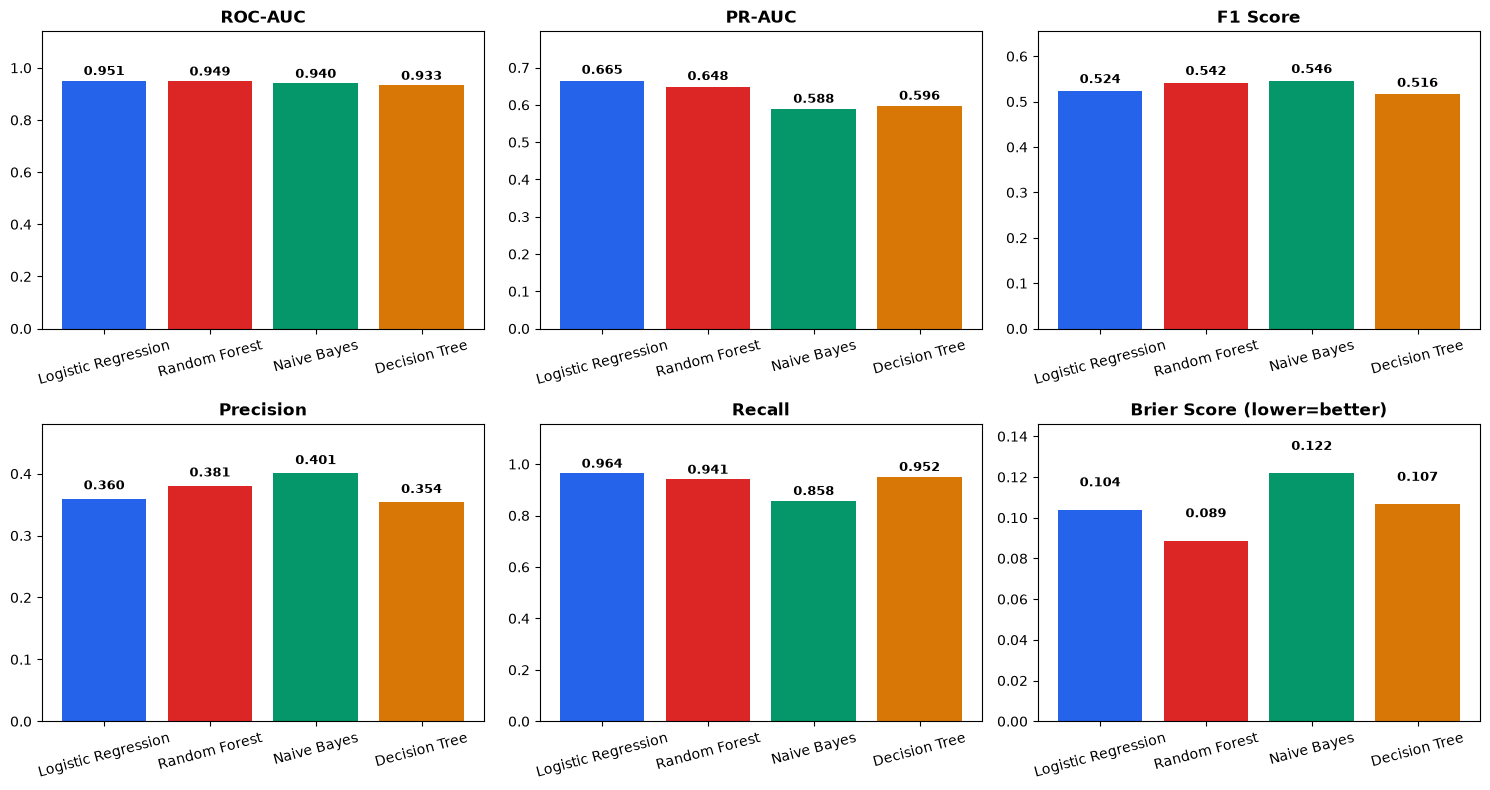

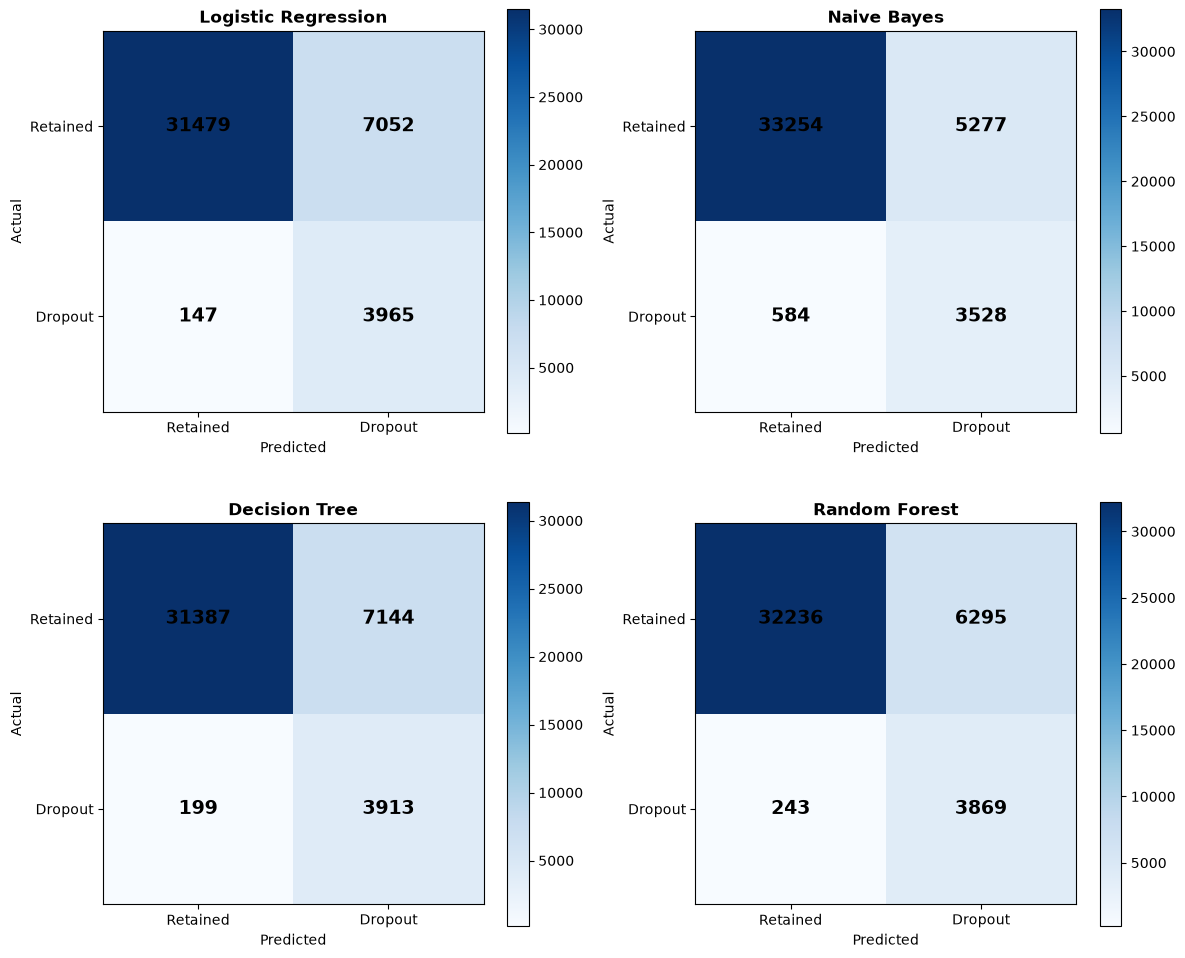

Saved: model_comparison_roc_pr.png, model_comparison_metrics.png, model_comparison_confusion.png


In [21]:
# ========== MODEL COMPARISON: LR, NB, DT, RF ==========
import pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, 
                             f1_score, precision_score, recall_score,
                             brier_score_loss, classification_report,
                             confusion_matrix)
import warnings
warnings.filterwarnings('ignore')

# Load engineered features
with open('df_fe.pkl', 'rb') as f:
    df_fe = pickle.load(f)

# Load selected features
with open('selected_features.pkl', 'rb') as f:
    selected_features = pickle.load(f)

# Prepare data with ONE-HOT encoding for nominal categoricals
df_model = df_fe.copy()
df_model = pd.get_dummies(df_model, 
                          columns=['Gender', 'Housing_Status'], 
                          prefix=['Gender', 'Housing'], 
                          drop_first=False,
                          dtype=int)

onehot_cols = [c for c in df_model.columns if c.startswith('Gender_') or c.startswith('Housing_')]
feat_cols = [c for c in selected_features if c in df_model.columns] + onehot_cols

exclude = ['Student_ID', 'End_of_Semester_Status', 'Target_Dropout_Next_Sem',
           'Censored', 'Income_Bin', 'sem_gpa_invalid', 'target',
           'Gender', 'Housing_Status', 'End_of_Semester_Status_encoded']
feat_cols = [c for c in feat_cols if c not in exclude and df_model[c].dtype in ['int64', 'float64', 'int32', 'float32', 'uint8']]

df_clean = df_model[feat_cols + ['target', 'Student_ID']].dropna()
X = df_clean[feat_cols]
y = df_clean['target']
groups = df_clean['Student_ID']

print(f'Feature matrix: {X.shape}')
print(f'Target distribution: {y.value_counts().to_dict()}')
print(f'Unique students: {groups.nunique()}')
print(f'Features: {len(feat_cols)}')

# Define models
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            class_weight='balanced', max_iter=1000,
            random_state=42, solver='lbfgs', C=1.0
        ))
    ]),
    'Naive Bayes': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
}

# Grouped Cross-Validation
gkf = GroupKFold(n_splits=5)

results = {}

for name, model in models.items():
    print(f'\n--- {name} ---')
    
    # Cross-validated predictions
    y_pred_proba = cross_val_predict(model, X, y, cv=gkf, groups=groups,
                                     method='predict_proba', n_jobs=-1)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)
    
    # Metrics
    roc_auc = roc_auc_score(y, y_pred_proba)
    pr_auc = average_precision_score(y, y_pred_proba)
    f1 = f1_score(y, y_pred)
    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    brier = brier_score_loss(y, y_pred_proba)
    
    results[name] = {
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'f1': f1,
        'precision': precision,
        'recall': recall,
        'brier': brier,
        'y_pred_proba': y_pred_proba,
        'y_pred': y_pred
    }
    
    print(f'  ROC-AUC:  {roc_auc:.4f}')
    print(f'  PR-AUC:   {pr_auc:.4f}')
    print(f'  F1:       {f1:.4f}')
    print(f'  Precision:{precision:.4f}')
    print(f'  Recall:   {recall:.4f}')
    print(f'  Brier:    {brier:.4f}')

# Summary table
summary_df = pd.DataFrame({
    name: {k: v for k, v in res.items() if k not in ['y_pred_proba', 'y_pred']}
    for name, res in results.items()
}).T
summary_df = summary_df[['roc_auc', 'pr_auc', 'f1', 'precision', 'recall', 'brier']]
summary_df = summary_df.sort_values('roc_auc', ascending=False)

print('\n========== MODEL COMPARISON SUMMARY ==========')
print(summary_df.round(4).to_string())

# Save results
with open('model_comparison_results.pkl', 'wb') as f:
    pickle.dump(results, f)
print('\nSaved model_comparison_results.pkl')

# ========== VISUALIZATIONS ==========
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix
import numpy as np

colors = {'Logistic Regression': '#2563eb', 'Naive Bayes': '#059669', 
          'Decision Tree': '#d97706', 'Random Forest': '#dc2626'}

# 1. ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, res in results.items():
    RocCurveDisplay.from_predictions(y, res['y_pred_proba'], ax=axes[0], name=name)
    axes[0].get_lines()[-1].set_color(colors[name])
    PrecisionRecallDisplay.from_predictions(y, res['y_pred_proba'], ax=axes[1], name=name)
    axes[1].get_lines()[-1].set_color(colors[name])

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('ROC Curves Comparison', weight='bold')
axes[0].legend()

axes[1].axhline(y.mean(), color='k', linestyle='--', alpha=0.5, label=f'Baseline ({y.mean():.3f})')
axes[1].set_title('Precision-Recall Curves Comparison', weight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('model_comparison_roc_pr.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# 2. Metrics bar chart
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
metrics = ['roc_auc', 'pr_auc', 'f1', 'precision', 'recall', 'brier']
metric_names = ['ROC-AUC', 'PR-AUC', 'F1 Score', 'Precision', 'Recall', 'Brier Score (lower=better)']

for idx, (metric, mname) in enumerate(zip(metrics, metric_names)):
    ax = axes[idx // 3, idx % 3]
    values = [results[name][metric] for name in summary_df.index]
    bars = ax.bar(summary_df.index, values, color=[colors[n] for n in summary_df.index])
    ax.set_title(mname, weight='bold')
    ax.set_ylim(0, max(values) * 1.2 if max(values) > 0 else 1)
    ax.tick_params(axis='x', rotation=15)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, weight='bold')

plt.tight_layout()
plt.savefig('model_comparison_metrics.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# 3. Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for idx, (name, res) in enumerate(results.items()):
    ax = axes[idx // 2, idx % 2]
    cm = confusion_matrix(y, res['y_pred'])
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.set_title(f'{name}', weight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Retained', 'Dropout'])
    ax.set_yticklabels(['Retained', 'Dropout'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=14, weight='bold')
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('model_comparison_confusion.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print('Saved: model_comparison_roc_pr.png, model_comparison_metrics.png, model_comparison_confusion.png')


========== THRESHOLD ANALYSIS ==========
Default threshold (0.5):
  Precision: 0.3598
  Recall:    0.9662
  F1:        0.5244

Optimal F1 threshold: 0.8032
  Precision: 0.5495
  Recall:    0.7060
  F1:        0.6180

Youden J threshold: 0.4924
  Sensitivity: 0.9691
  Specificity: 0.8144



========== COST-BENEFIT ANALYSIS ==========
Cost FP: $1,000 | Cost FN: $10,000 | Benefit TP: $8,000
Best threshold (max net benefit): 0.2914
Max net benefit: $24,032,000

At threshold 0.2914:
  TP: 4106, FP: 8756, TN: 29775, FN: 6
  Precision: 0.3192
  Recall:    0.9985
  Net Benefit: $24,032,000

========== SUBGROUP ANALYSIS (at optimal F1 threshold) ==========


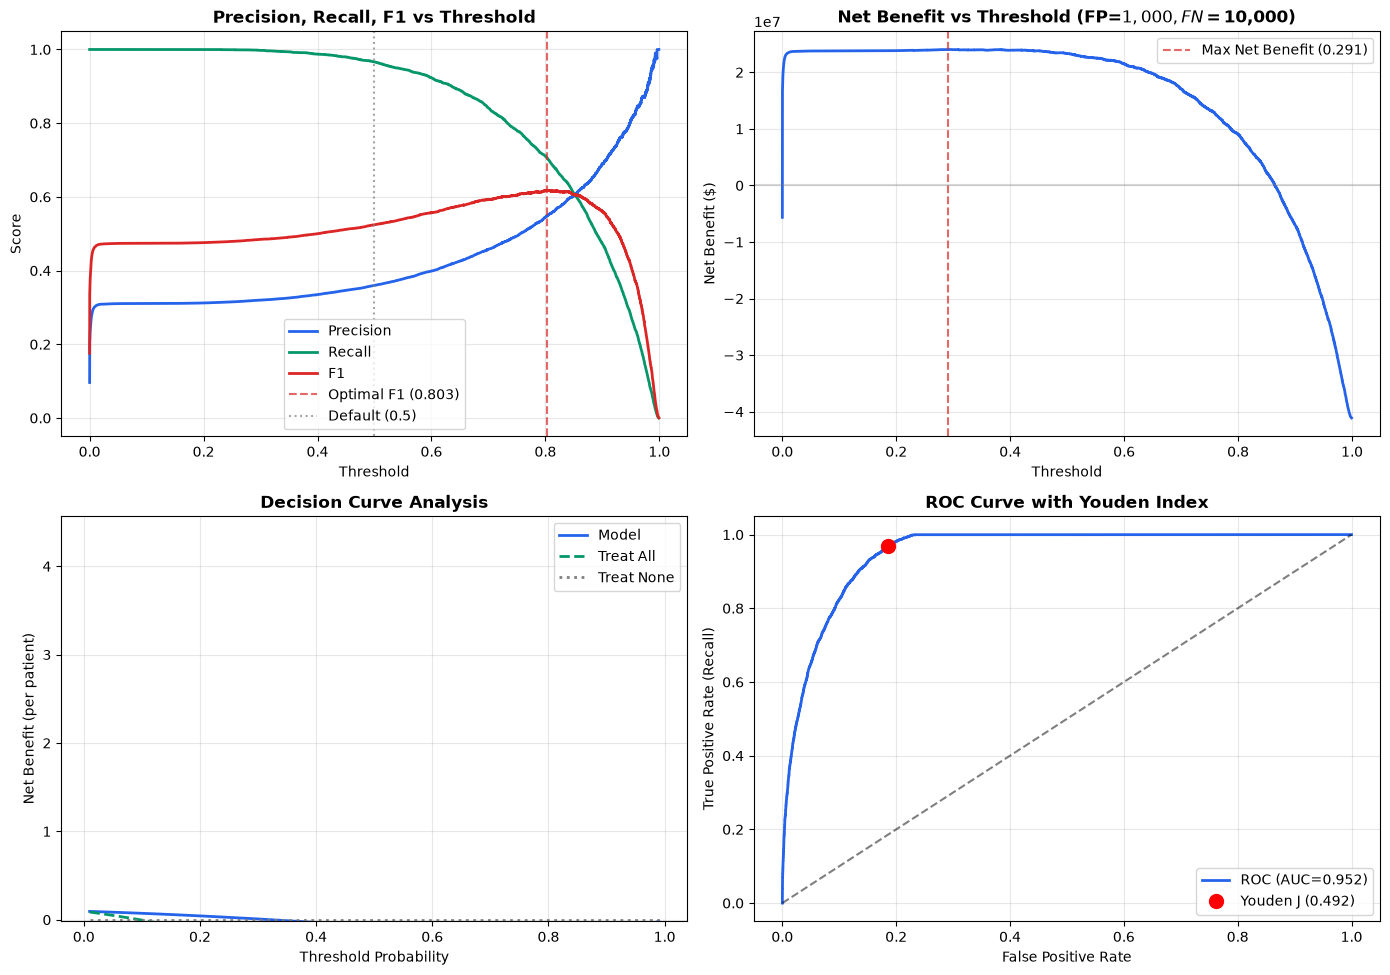


========== SUBGROUP PERFORMANCE SUMMARY ==========
Empty DataFrame
Columns: []
Index: []

Saved threshold_analysis_results.pkl and threshold_analysis.png


In [22]:
# ========== THRESHOLD ANALYSIS & COST-BENEFIT ==========
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import (precision_recall_curve, roc_curve,
                             confusion_matrix, classification_report)
import warnings
warnings.filterwarnings('ignore')

# Load best model (Logistic Regression) and data
with open('lr_model_no_leakage.pkl', 'rb') as f:
    pipe = pickle.load(f)

with open('df_fe.pkl', 'rb') as f:
    df_fe = pickle.load(f)

with open('selected_features.pkl', 'rb') as f:
    selected_features = pickle.load(f)

# Prepare data (same as before)
df_model = df_fe.copy()
df_model = pd.get_dummies(df_model, 
                          columns=['Gender', 'Housing_Status'], 
                          prefix=['Gender', 'Housing'], 
                          drop_first=False,
                          dtype=int)

onehot_cols = [c for c in df_model.columns if c.startswith('Gender_') or c.startswith('Housing_')]
feat_cols = [c for c in selected_features if c in df_model.columns] + onehot_cols

exclude = ['Student_ID', 'End_of_Semester_Status', 'Target_Dropout_Next_Sem',
           'Censored', 'Income_Bin', 'sem_gpa_invalid', 'target',
           'Gender', 'Housing_Status', 'End_of_Semester_Status_encoded']
feat_cols = [c for c in feat_cols if c not in exclude and df_model[c].dtype in ['int64', 'float64', 'int32', 'float32', 'uint8']]

df_clean = df_model[feat_cols + ['target', 'Student_ID']].dropna()
X = df_clean[feat_cols]
y = df_clean['target']
groups = df_clean['Student_ID']

# Get predicted probabilities from trained model
y_pred_proba = pipe.predict_proba(X)[:, 1]

# ========== 1. PRECISION-RECALL CURVE & THRESHOLDS ==========
precision, recall, thresholds = precision_recall_curve(y, y_pred_proba)

# F1 score for each threshold
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-10)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
optimal_f1 = f1_scores[optimal_idx]
optimal_precision = precision[optimal_idx]
optimal_recall = recall[optimal_idx]

# Youden's J statistic (sensitivity + specificity - 1)
fpr, tpr, roc_thresholds = roc_curve(y, y_pred_proba)
youden_j = tpr - fpr
youden_idx = np.argmax(youden_j)
youden_threshold = roc_thresholds[youden_idx]
youden_sensitivity = tpr[youden_idx]
youden_specificity = 1 - fpr[youden_idx]

print('========== THRESHOLD ANALYSIS ==========')
print(f'Default threshold (0.5):')
y_pred_default = (y_pred_proba >= 0.5).astype(int)
from sklearn.metrics import precision_score, recall_score, f1_score
print(f'  Precision: {precision_score(y, y_pred_default):.4f}')
print(f'  Recall:    {recall_score(y, y_pred_default):.4f}')
print(f'  F1:        {f1_score(y, y_pred_default):.4f}')

print(f'\nOptimal F1 threshold: {optimal_threshold:.4f}')
print(f'  Precision: {optimal_precision:.4f}')
print(f'  Recall:    {optimal_recall:.4f}')
print(f'  F1:        {optimal_f1:.4f}')

print(f'\nYouden J threshold: {youden_threshold:.4f}')
print(f'  Sensitivity: {youden_sensitivity:.4f}')
print(f'  Specificity: {youden_specificity:.4f}')

# ========== 2. COST-BENEFIT ANALYSIS ==========
# Define intervention costs (adjust based on your context)
cost_fp = 1000   # Cost of false alarm (intervene on retained student)
cost_fn = 10000  # Cost of missed dropout (lose student)
# Benefit of true positive (prevent dropout)
benefit_tp = 8000  # Estimated value of retaining a student

# Calculate net benefit for each threshold
net_benefits = []
for i, t in enumerate(thresholds):
    y_pred_t = (y_pred_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred_t).ravel()
    # Net benefit = benefit*TP - cost_fp*FP - cost_fn*FN
    net = benefit_tp * tp - cost_fp * fp - cost_fn * fn
    net_benefits.append(net)

best_idx = np.argmax(net_benefits)
best_threshold = thresholds[best_idx]
best_net_benefit = net_benefits[best_idx]

print(f'\n========== COST-BENEFIT ANALYSIS ==========')
print(f'Cost FP: ${cost_fp:,} | Cost FN: ${cost_fn:,} | Benefit TP: ${benefit_tp:,}')
print(f'Best threshold (max net benefit): {best_threshold:.4f}')
print(f'Max net benefit: ${best_net_benefit:,.0f}')

# Compare strategies
y_pred_best = (y_pred_proba >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y, y_pred_best).ravel()
print(f'\nAt threshold {best_threshold:.4f}:')
print(f'  TP: {tp}, FP: {fp}, TN: {tn}, FN: {fn}')
print(f'  Precision: {tp/(tp+fp):.4f}')
print(f'  Recall:    {tp/(tp+fn):.4f}')
print(f'  Net Benefit: ${best_net_benefit:,.0f}')

# ========== 3. DECISION CURVE ANALYSIS ==========
# Net benefit across threshold range (per 100 students)
n = len(y)
prevalence = y.mean()

threshold_range = np.linspace(0.01, 0.99, 99)
net_benefit_model = []
net_benefit_all = []
net_benefit_none = []

for t in threshold_range:
    y_pred_t = (y_pred_proba >= t).astype(int)
    tp = ((y == 1) & (y_pred_t == 1)).sum()
    fp = ((y == 0) & (y_pred_t == 1)).sum()
    # Net benefit per patient = TP/n - FP/n * (t/(1-t))
    nb = tp/n - fp/n * (t/(1-t))
    net_benefit_model.append(nb)
    # Treat all: everyone gets intervention
    nb_all = prevalence - (1-prevalence) * (t/(1-t))
    net_benefit_all.append(nb_all)
    # Treat none: zero
    net_benefit_none.append(0)

# ========== 4. SUBGROUP ANALYSIS ==========
print('\n========== SUBGROUP ANALYSIS (at optimal F1 threshold) ==========')
y_pred_opt = (y_pred_proba >= optimal_threshold).astype(int)
df_clean = df_clean.copy()
df_clean['y_pred'] = y_pred_opt
df_clean['y_true'] = y
df_clean['y_prob'] = y_pred_proba

for col in ['Gender', 'Housing_Status', 'Scholarship']:
    if col in df_clean.columns:
        print(f'\n--- {col} ---')
        for val in sorted(df_clean[col].unique()):
            mask = df_clean[col] == val
            if mask.sum() > 10:
                sub_y = df_clean.loc[mask, 'y_true']
                sub_pred = df_clean.loc[mask, 'y_pred']
                from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
                p = precision_score(sub_y, sub_pred, zero_division=0)
                r = recall_score(sub_y, sub_pred, zero_division=0)
                f1 = f1_score(sub_y, sub_pred, zero_division=0)
                try:
                    auc = roc_auc_score(sub_y, df_clean.loc[mask, 'y_prob'])
                except:
                    auc = np.nan
                print(f'  {val}: n={mask.sum()}, P={p:.3f}, R={r:.3f}, F1={f1:.3f}, AUC={auc:.3f}')

# ========== 5. VISUALIZATIONS ==========
import matplotlib.pyplot as plt

# Fig 1: Precision-Recall with thresholds
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.plot(thresholds, precision[:-1], label='Precision', color='#2563eb', linewidth=2)
ax.plot(thresholds, recall[:-1], label='Recall', color='#059669', linewidth=2)
ax.plot(thresholds, f1_scores, label='F1', color='#dc2626', linewidth=2)
ax.axvline(optimal_threshold, color='#dc2626', linestyle='--', alpha=0.7, label=f'Optimal F1 ({optimal_threshold:.3f})')
ax.axvline(0.5, color='gray', linestyle=':', alpha=0.7, label='Default (0.5)')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Precision, Recall, F1 vs Threshold', weight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Fig 2: Cost-benefit
ax = axes[0, 1]
ax.plot(thresholds, net_benefits, color='#2563eb', linewidth=2)
ax.axvline(best_threshold, color='#dc2626', linestyle='--', alpha=0.7, label=f'Max Net Benefit ({best_threshold:.3f})')
ax.axhline(0, color='gray', linestyle='-', alpha=0.3)
ax.set_xlabel('Threshold')
ax.set_ylabel('Net Benefit ($)')
ax.set_title(f'Net Benefit vs Threshold (FP=${cost_fp:,}, FN=${cost_fn:,})', weight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Fig 3: Decision Curve Analysis
ax = axes[1, 0]
ax.plot(threshold_range, net_benefit_model, label='Model', color='#2563eb', linewidth=2)
ax.plot(threshold_range, net_benefit_all, label='Treat All', color='#059669', linewidth=2, linestyle='--')
ax.plot(threshold_range, net_benefit_none, label='Treat None', color='gray', linewidth=2, linestyle=':')
ax.set_xlabel('Threshold Probability')
ax.set_ylabel('Net Benefit (per patient)')
ax.set_title('Decision Curve Analysis', weight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=-0.02)

# Fig 4: ROC with Youden
ax = axes[1, 1]
ax.plot(fpr, tpr, color='#2563eb', linewidth=2, label=f'ROC (AUC={roc_auc_score(y, y_pred_proba):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.plot(fpr[youden_idx], tpr[youden_idx], 'ro', markersize=10, label=f'Youden J ({youden_threshold:.3f})')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve with Youden Index', weight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('threshold_analysis.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# Fig 5: Subgroup performance heatmap
subgroup_data = []
for col in ['Gender', 'Housing_Status', 'Scholarship']:
    if col in df_clean.columns:
        for val in sorted(df_clean[col].unique()):
            mask = df_clean[col] == val
            if mask.sum() > 10:
                sub_y = df_clean.loc[mask, 'y_true']
                sub_pred = df_clean.loc[mask, 'y_pred']
                from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
                p = precision_score(sub_y, sub_pred, zero_division=0)
                r = recall_score(sub_y, sub_pred, zero_division=0)
                f1 = f1_score(sub_y, sub_pred, zero_division=0)
                try:
                    auc = roc_auc_score(sub_y, df_clean.loc[mask, 'y_prob'])
                except:
                    auc = np.nan
                subgroup_data.append({
                    'Feature': col,
                    'Value': str(val),
                    'n': mask.sum(),
                    'Precision': p,
                    'Recall': r,
                    'F1': f1,
                    'AUC': auc
                })

subgroup_df = pd.DataFrame(subgroup_data)
print('\n========== SUBGROUP PERFORMANCE SUMMARY ==========')
print(subgroup_df.to_string(index=False))

with open('threshold_analysis_results.pkl', 'wb') as f:
    pickle.dump({
        'optimal_threshold': optimal_threshold,
        'optimal_f1': optimal_f1,
        'optimal_precision': optimal_precision,
        'optimal_recall': optimal_recall,
        'youden_threshold': youden_threshold,
        'youden_sensitivity': youden_sensitivity,
        'youden_specificity': youden_specificity,
        'best_threshold_cost': best_threshold,
        'best_net_benefit': best_net_benefit,
        'cost_params': {'fp': cost_fp, 'fn': cost_fn, 'tp': benefit_tp},
        'subgroup_df': subgroup_df.to_dict('records')
    }, f)
print('\nSaved threshold_analysis_results.pkl and threshold_analysis.png')


In [23]:
# ========== LIGHTWEIGHT HYPERPARAMETER TUNING (GridSearchCV, 3-fold) ==========
import pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# Load data
with open('df_fe.pkl', 'rb') as f:
    df_fe = pickle.load(f)

with open('selected_features.pkl', 'rb') as f:
    selected_features = pickle.load(f)

# Prepare data
df_model = df_fe.copy()
df_model = pd.get_dummies(df_model, 
                          columns=['Gender', 'Housing_Status'], 
                          prefix=['Gender', 'Housing'], 
                          drop_first=False,
                          dtype=int)

onehot_cols = [c for c in df_model.columns if c.startswith('Gender_') or c.startswith('Housing_')]
feat_cols = [c for c in selected_features if c in df_model.columns] + onehot_cols

exclude = ['Student_ID', 'End_of_Semester_Status', 'Target_Dropout_Next_Sem',
           'Censored', 'Income_Bin', 'sem_gpa_invalid', 'target',
           'Gender', 'Housing_Status', 'End_of_Semester_Status_encoded']
feat_cols = [c for c in feat_cols if c not in exclude and df_model[c].dtype in ['int64', 'float64', 'int32', 'float32', 'uint8']]

df_clean = df_model[feat_cols + ['target', 'Student_ID']].dropna()
X = df_clean[feat_cols]
y = df_clean['target']
groups = df_clean['Student_ID']

print(f'Data: {X.shape}, Target: {y.mean():.3f}')

# ========== 1. LOGISTIC REGRESSION ==========
print('\n--- Logistic Regression Grid Search ---')
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
        solver='lbfgs'
    ))
])

param_lr = {
    'model__C': [0.01, 0.1, 1, 10, 100],
}

gkf = GroupKFold(n_splits=3)
search_lr = GridSearchCV(
    pipe_lr, param_lr, cv=gkf, scoring='roc_auc',
    n_jobs=-1, verbose=1
)
search_lr.fit(X, y, groups=groups)
print(f'Best LR C: {search_lr.best_params_}')
print(f'Best ROC-AUC: {search_lr.best_score_:.4f}')

# ========== 2. RANDOM FOREST ==========
print('\n--- Random Forest Grid Search ---')
rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

param_rf = {
    'n_estimators': [200, 400],
    'max_depth': [8, 12, 16],
    'min_samples_split': [10, 20],
    'min_samples_leaf': [5, 10],
}

search_rf = GridSearchCV(
    rf, param_rf, cv=gkf, scoring='roc_auc',
    n_jobs=-1, verbose=1
)
search_rf.fit(X, y, groups=groups)
print(f'Best RF: {search_rf.best_params_}')
print(f'Best ROC-AUC: {search_rf.best_score_:.4f}')

# ========== 3. DECISION TREE (quick) ==========
print('\n--- Decision Tree Grid Search ---')
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

param_dt = {
    'max_depth': [6, 8, 10, 12],
    'min_samples_split': [20, 50],
    'min_samples_leaf': [10, 20],
}

search_dt = GridSearchCV(
    dt, param_dt, cv=gkf, scoring='roc_auc',
    n_jobs=-1, verbose=1
)
search_dt.fit(X, y, groups=groups)
print(f'Best DT: {search_dt.best_params_}')
print(f'Best ROC-AUC: {search_dt.best_score_:.4f}')

# ========== SUMMARY ==========
tuned_results = {
    'Logistic Regression': {'best_params': search_lr.best_params_, 'best_roc_auc': search_lr.best_score_},
    'Random Forest': {'best_params': search_rf.best_params_, 'best_roc_auc': search_rf.best_score_},
    'Decision Tree': {'best_params': search_dt.best_params_, 'best_roc_auc': search_dt.best_score_},
}

print('\n========== TUNED MODEL COMPARISON ==========')
for name, res in tuned_results.items():
    print(f'{name}: ROC-AUC={res["best_roc_auc"]:.4f}, params={res["best_params"]}')

# Save best models
best_models = {
    'lr': search_lr.best_estimator_,
    'rf': search_rf.best_estimator_,
    'dt': search_dt.best_estimator_,
}
with open('best_tuned_models.pkl', 'wb') as f:
    pickle.dump(best_models, f)
with open('tuning_results.pkl', 'wb') as f:
    pickle.dump(tuned_results, f)
print('\nSaved best_tuned_models.pkl and tuning_results.pkl')


Data: (42643, 38), Target: 0.096

--- Logistic Regression Grid Search ---


Fitting 3 folds for each of 5 candidates, totalling 15 fits


Best LR C: {'model__C': 1}
Best ROC-AUC: 0.9509

--- Random Forest Grid Search ---
Fitting 3 folds for each of 24 candidates, totalling 72 fits


Best RF: {'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 10, 'n_estimators': 400}
Best ROC-AUC: 0.9493

--- Decision Tree Grid Search ---
Fitting 3 folds for each of 16 candidates, totalling 48 fits


Best DT: {'max_depth': 6, 'min_samples_leaf': 20, 'min_samples_split': 20}
Best ROC-AUC: 0.9413

========== TUNED MODEL COMPARISON ==========
Logistic Regression: ROC-AUC=0.9509, params={'model__C': 1}
Random Forest: ROC-AUC=0.9493, params={'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 10, 'n_estimators': 400}
Decision Tree: ROC-AUC=0.9413, params={'max_depth': 6, 'min_samples_leaf': 20, 'min_samples_split': 20}

Saved best_tuned_models.pkl and tuning_results.pkl


In [23]:
# Save cleaned data
df.to_csv('academic_survival_longitudinal_cleaned.csv', index=False)
print('Saved cleaned data to academic_survival_longitudinal_cleaned.csv')
print('Final shape:', df.shape)


Saved cleaned data to academic_survival_longitudinal_cleaned.csv
Final shape: (79239, 24)


## Next steps

- Confirm `academic_survival_longitudinal (1).csv` is in this folder before running.
- Install dependencies: `conda install pandas matplotlib`
- Review invalid Sem_GPA rows flagged in the cleaning cell.
- Adjust outlier capping / imputation strategy as needed.
- Add statistical tests or survival modeling using `Censored` and `Target_Dropout_Next_Sem`.
